<a href="https://colab.research.google.com/github/akankshabhuyan-tech/PhishGuard_AIMLMiniProject26/blob/main/AIML_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving PhiUSIIL_Phishing_URL_Dataset.csv to PhiUSIIL_Phishing_URL_Dataset (3).csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load uploaded CSV
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

# Display basic information
print("DATASET LOADED SUCCESSFULLY")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


DATASET LOADED SUCCESSFULLY

Dataset Shape:
(235795, 56)

Column Names:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

First 5 

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64

In [ ]:

# STEP 2.1: DUPLICATE URL AUDIT

# Check whether URL values are missing
print("Missing URLs:", df["URL"].isnull().sum())

# Check total duplicate URLs
print("Duplicate URLs:", df["URL"].duplicated().sum())

# Count unique URLs
print("Unique URLs:", df["URL"].nunique())

# Find URLs that appear more than once
duplicate_urls = df[df["URL"].duplicated(keep=False)]

print("\nRows belonging to duplicate URLs:")
print(len(duplicate_urls))

display(duplicate_urls[["URL", "label"]].head(10))


Missing URLs: 0
Duplicate URLs: 425
Unique URLs: 235370

Rows belonging to duplicate URLs:
850


,URL,label
87,https://att-104164.weeblysite.com/,0
978,https://etiliseramik.com/wp-includes/vector/lo...,0
1636,https://snapdragon-magic-flag.glitch.me/navyfe...,0
2474,http://my-business-108580.square.site/,0
2543,https://facebook-help-600674518635606.firebase...,0
2583,http://splaudioprofessional.com/wp-content/net...,0
2852,https://objectstorage.ap-singapore-1.oracleclo...,0
3055,https://yahoo-109157.weeblysite.com/,0
3393,https://www.ak3.duckdns.org/,0
3403,https://dev-itaupysegura.pantheonsite.io/,0


In [ ]:

# STEP 2.2: CHECK CONFLICTING LABELS

url_label_counts = df.groupby("URL")["label"].nunique()

conflicting_urls = url_label_counts[url_label_counts > 1]

print("Number of URLs with conflicting labels:", len(conflicting_urls))

if len(conflicting_urls) > 0:
    print("\nExamples of conflicting URLs:")
    display(
        df[df["URL"].isin(conflicting_urls.index)][["URL", "label"]].head(10)
    )
else:
    print("No conflicting URL labels found.")


Number of URLs with conflicting labels: 0
No conflicting URL labels found.


In [ ]:

# STEP 4: SELECT URL-BASED FEATURES

url_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

# Create a separate dataframe
model_df = df[url_features + ["label"]].copy()

print("Original dataset shape:", df.shape)
print("URL-only dataset shape:", model_df.shape)

print("\nSelected features:")
print(url_features)

print("\nTarget distribution:")
print(model_df["label"].value_counts())

print("\nMissing values:")
print(model_df.isnull().sum().sum())

display(model_df.head())


Original dataset shape: (235795, 56)
URL-only dataset shape: (235795, 19)

Selected features:
['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']

Target distribution:
label
1    134850
0    100945
Name: count, dtype: int64

Missing values:
0


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,label
0,31,24,0,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,1
1,23,16,0,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,1
2,29,22,0,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,1
3,26,19,0,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,1
4,33,26,0,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,1


In [ ]:

# STEP 3.1: CHECK DUPLICATE FEATURE CONSISTENCY

feature_variations = df.groupby("URL")[url_features].nunique()

inconsistent_features = feature_variations.gt(1).sum(axis=0)

print("Features with inconsistent values for the same URL:")
print(inconsistent_features[inconsistent_features > 0])

inconsistent_url_count = (
    feature_variations.gt(1).any(axis=1).sum()
)

print("\nNumber of URLs with inconsistent feature values:",
      inconsistent_url_count)


Features with inconsistent values for the same URL:
URLLength                     425
ObfuscationRatio                1
NoOfLettersInURL              129
LetterRatioInURL              424
NoOfDegitsInURL                 7
DegitRatioInURL               250
NoOfOtherSpecialCharsInURL    289
SpacialCharRatioInURL         407
dtype: int64

Number of URLs with inconsistent feature values: 425


In [ ]:

# STEP 3.2: REMOVE DUPLICATE URL RECORDS

# Keep the first occurrence of each URL
df_clean = df.drop_duplicates(
    subset="URL",
    keep="first"
).copy()

# Recreate the URL-only modelling dataset
model_df = df_clean[url_features + ["label"]].copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Model dataset shape:", model_df.shape)

print("\nRemaining duplicate URLs:",
      df_clean["URL"].duplicated().sum())

print("\nMissing values:",
      model_df.isnull().sum().sum())

print("\nClass distribution after cleaning:")
print(model_df["label"].value_counts())

print("\nPercentage distribution:")
print(
    model_df["label"].value_counts(normalize=True) * 100
)


Original dataset shape: (235795, 56)
Cleaned dataset shape: (235370, 56)
Model dataset shape: (235370, 19)

Remaining duplicate URLs: 0

Missing values: 0

Class distribution after cleaning:
label
1    134850
0    100520
Name: count, dtype: int64

Percentage distribution:
label
1    57.292773
0    42.707227
Name: proportion, dtype: float64


In [ ]:

# STEP 4.1: VERIFY CLEANED DATASET

print("Cleaned dataset shape:", df_clean.shape)
print("Model dataset shape:", model_df.shape)

print("\nDuplicate URLs remaining:",
      df_clean["URL"].duplicated().sum())

print("\nMissing values:")
print(model_df.isnull().sum().sum())

print("\nClass distribution:")
print(model_df["label"].value_counts())

print("\nStatistical summary:")
display(model_df.describe())


Cleaned dataset shape: (235370, 56)
Model dataset shape: (235370, 19)

Duplicate URLs remaining: 0

Missing values:
0

Class distribution:
label
1    134850
0    100520
Name: count, dtype: int64

Statistical summary:


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,label
count,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000,235370.000000
mean,34.545516,21.456022,0.002702,2.764269,1.164957,0.002052,0.024880,0.000138,19.405600,0.515749,1.875732,0.028516,0.062327,0.029422,0.025080,2.335977,0.063249,0.782717,0.572928
std,41.332730,9.127733,0.051912,0.599667,0.600695,0.045254,1.877922,0.003818,29.099537,0.123234,11.892529,0.070801,0.935532,0.193593,0.837185,3.527556,0.032363,0.412398,0.494654
min,13.000000,4.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,10.000000,0.435000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.038000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,14.000000,0.519000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.050000,1.000000,1.000000
75%,34.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,20.000000,0.594000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.083000,1.000000,1.000000
max,6097.000000,110.000000,1.000000,13.000000,10.000000,1.000000,447.000000,0.348000,5191.000000,0.926000,2011.000000,0.684000,176.000000,4.000000,149.000000,499.000000,0.397000,1.000000,1.000000


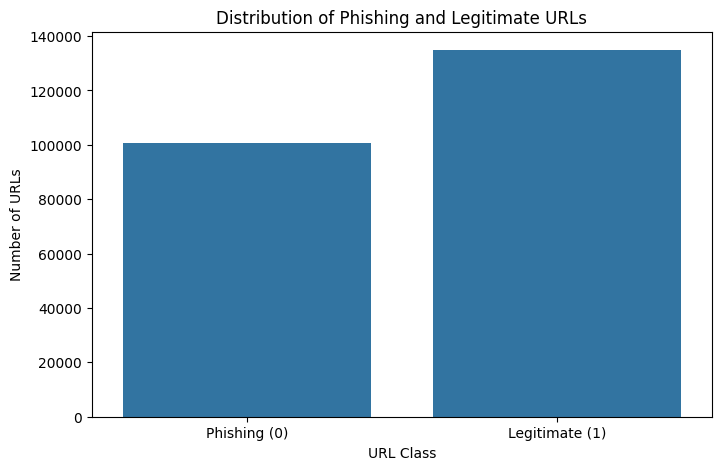

Class percentages:
label
1    57.292773
0    42.707227
Name: proportion, dtype: float64


In [ ]:

# STEP 4.2: CLASS DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=model_df,
    x="label"
)

plt.title("Distribution of Phishing and Legitimate URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

plt.xticks(
    [0, 1],
    ["Phishing (0)", "Legitimate (1)"]
)

plt.show()

# Calculate percentages
class_percentages = (
    model_df["label"]
    .value_counts(normalize=True) * 100
)

print("Class percentages:")
print(class_percentages)


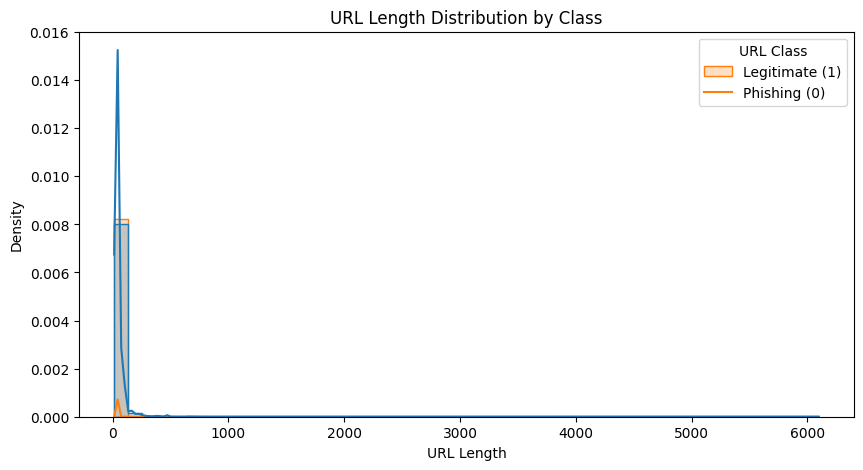

In [ ]:

# STEP 4.3: URL LENGTH DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=model_df,
    x="URLLength",
    hue="label",
    bins=50,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("URL Length Distribution by Class")
plt.xlabel("URL Length")
plt.ylabel("Density")

plt.legend(
    title="URL Class",
    labels=["Legitimate (1)", "Phishing (0)"]
)

plt.show()


In [ ]:

# STEP 4.4: FEATURE COMPARISON

feature_comparison = model_df.groupby("label")[url_features].mean().T

feature_comparison.columns = [
    "Phishing (0)",
    "Legitimate (1)"
]

feature_comparison["Difference"] = (
    feature_comparison["Phishing (0)"]
    - feature_comparison["Legitimate (1)"]
)

display(
    feature_comparison.sort_values(
        by="Difference",
        key=abs,
        ascending=False
    )
)


,Phishing (0),Legitimate (1),Difference
URLLength,45.702845,26.228610,19.474236
NoOfLettersInURL,28.088669,12.933059,15.155610
DomainLength,24.444150,19.228610,5.215541
NoOfDegitsInURL,4.324194,0.050597,4.273597
NoOfOtherSpecialCharsInURL,3.799771,1.244835,2.554936
IsHTTPS,0.491226,1.000000,-0.508774
NoOfEqualsInURL,0.145941,0.000000,0.145941
TLDLength,2.819121,2.723382,0.095739
LetterRatioInURL,0.568128,0.476705,0.091424
NoOfQMarkInURL,0.068892,0.000000,0.068892


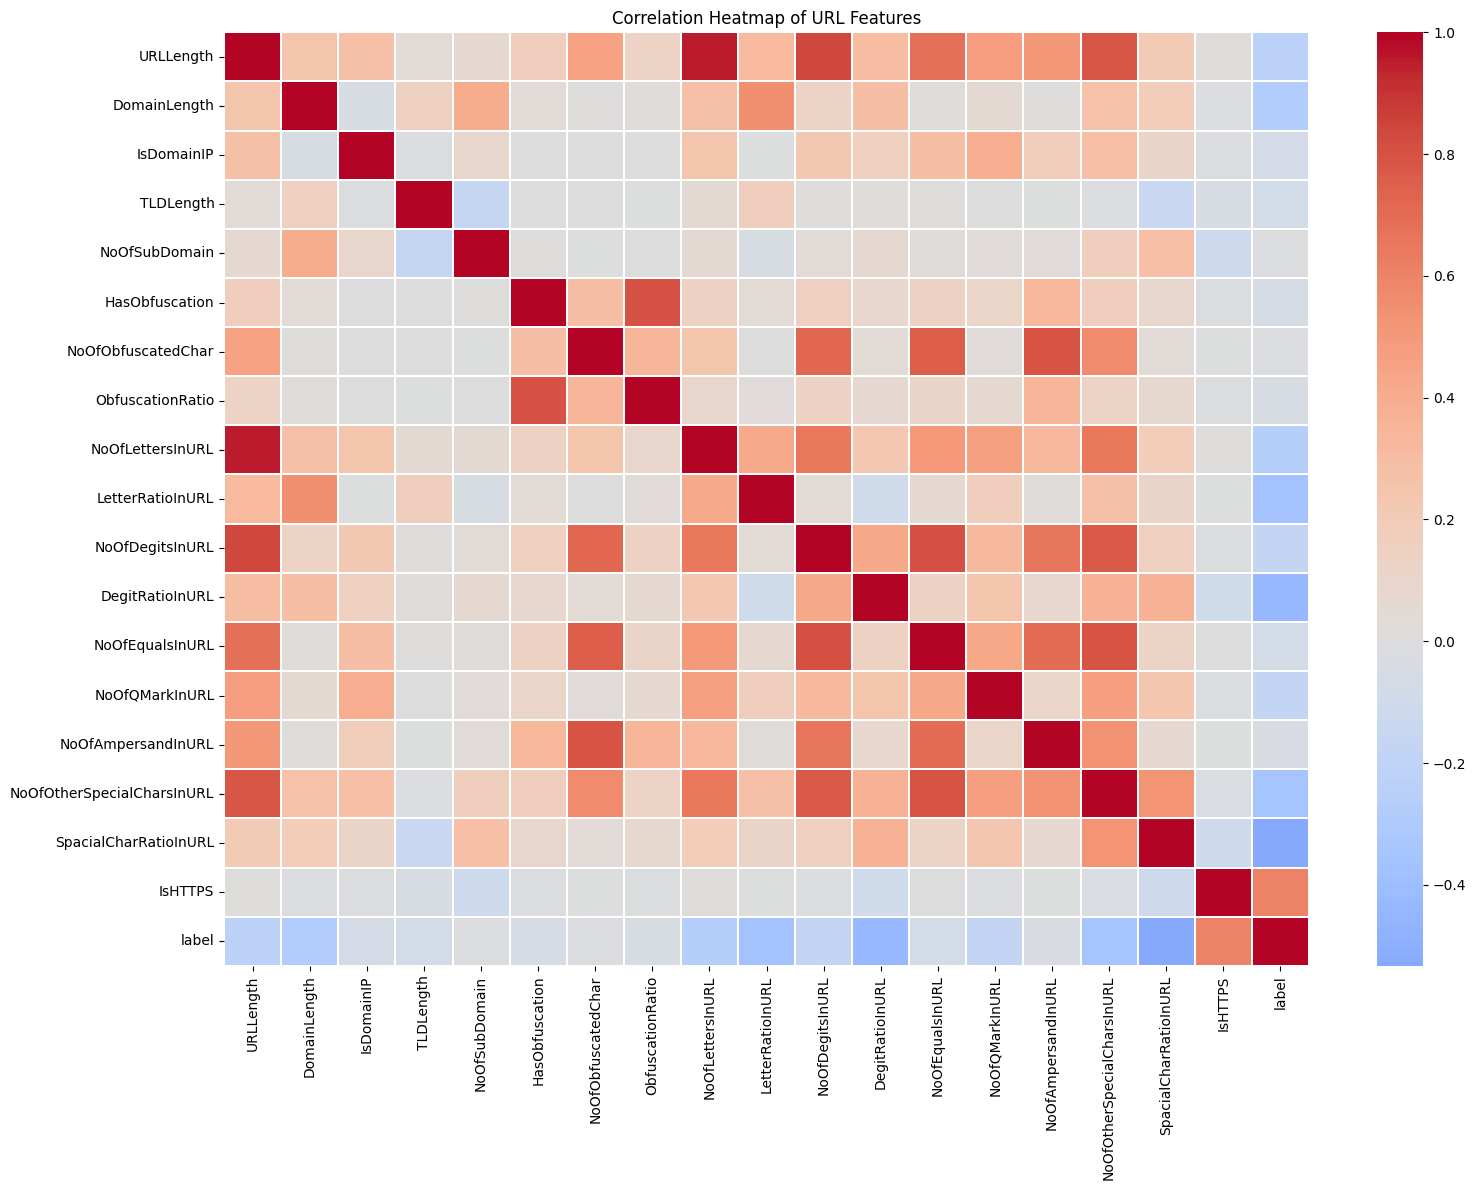

In [ ]:

# STEP 4.5: CORRELATION HEATMAP

correlation_matrix = model_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap of URL Features")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 4.5.1: HIGHLY CORRELATED FEATURE PAIRS

corr_values = model_df[url_features].corr()

high_corr_pairs = []

for i in range(len(url_features)):
    for j in range(i + 1, len(url_features)):

        correlation = corr_values.iloc[i, j]

        if abs(correlation) > 0.80:
            high_corr_pairs.append(
                (url_features[i], url_features[j], correlation)
            )

print("Highly correlated feature pairs:")

if high_corr_pairs:
    for feature1, feature2, value in high_corr_pairs:
        print(feature1, "<->", feature2, ":", round(value, 3))
else:
    print("No feature pairs above 0.80 correlation.")


Highly correlated feature pairs:
URLLength <-> NoOfLettersInURL : 0.956
URLLength <-> NoOfDegitsInURL : 0.836
NoOfDegitsInURL <-> NoOfEqualsInURL : 0.806


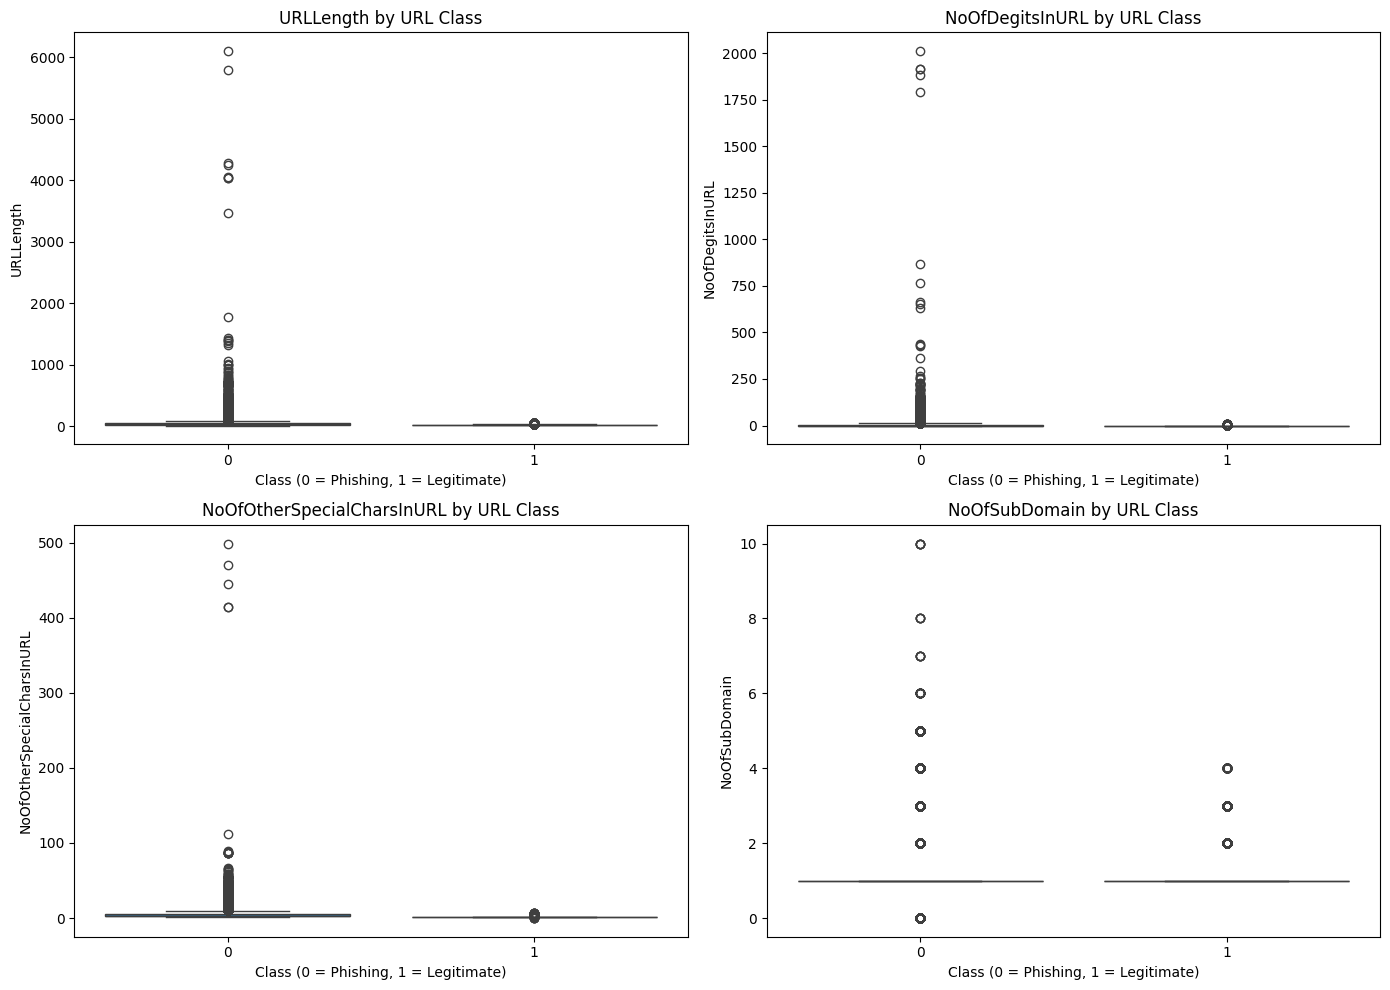

In [ ]:

# STEP 4.6: FEATURE DISTRIBUTION COMPARISON

features_to_plot = [
    "URLLength",
    "NoOfDegitsInURL",
    "NoOfOtherSpecialCharsInURL",
    "NoOfSubDomain"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features_to_plot, axes.flatten()):

    sns.boxplot(
        data=model_df,
        x="label",
        y=feature,
        hue="label",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{feature} by URL Class")
    ax.set_xlabel("Class (0 = Phishing, 1 = Legitimate)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


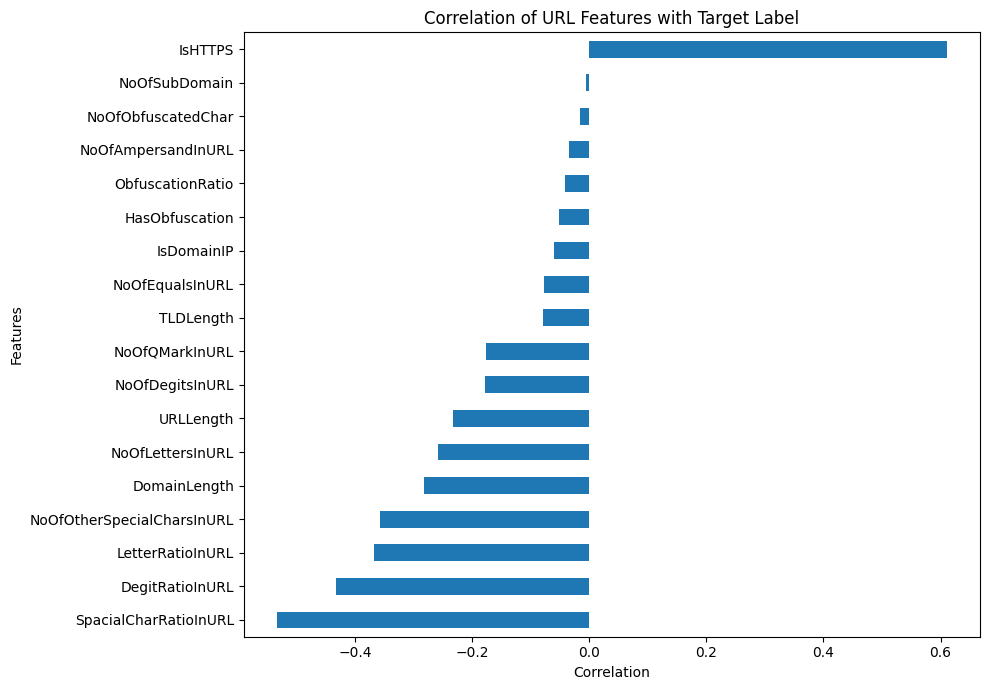

Feature correlations with target:


,Correlation with Label
SpacialCharRatioInURL,-0.533003
DegitRatioInURL,-0.431896
LetterRatioInURL,-0.366970
NoOfOtherSpecialCharsInURL,-0.358268
DomainLength,-0.282643
NoOfLettersInURL,-0.257626
URLLength,-0.233060
NoOfDegitsInURL,-0.177755
NoOfQMarkInURL,-0.176027
TLDLength,-0.078973


In [ ]:

# STEP 4.7: FEATURE CORRELATION WITH TARGET

target_correlation = (
    model_df.corr()["label"]
    .drop("label")
    .sort_values()
)

plt.figure(figsize=(10, 7))

target_correlation.plot(
    kind="barh"
)

plt.title("Correlation of URL Features with Target Label")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print("Feature correlations with target:")
display(target_correlation.to_frame("Correlation with Label"))


In [ ]:

# STEP 5.1: SEPARATE FEATURES AND TARGET

X = model_df[url_features].copy()
y = model_df["label"].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget distribution:")
print(y.value_counts())


Input features shape: (235370, 18)
Target shape: (235370,)

Input features:
   URLLength  DomainLength  IsDomainIP  TLDLength  NoOfSubDomain  \
0         31            24           0          3              1   
1         23            16           0          2              1   
2         29            22           0          2              2   
3         26            19           0          3              1   
4         33            26           0          3              1   

   HasObfuscation  NoOfObfuscatedChar  ObfuscationRatio  NoOfLettersInURL  \
0               0                   0               0.0                18   
1               0                   0               0.0                 9   
2               0                   0               0.0                15   
3               0                   0               0.0                13   
4               0                   0               0.0                20   

   LetterRatioInURL  NoOfDegitsInURL  DegitRatioInUR

In [ ]:

# STEP 5.3: DOMAIN-AWARE TRAIN-VALIDATION-TEST SPLIT

from sklearn.model_selection import GroupShuffleSplit

# Reset indexes to keep all arrays aligned
X = model_df[url_features].reset_index(drop=True)
y = model_df["label"].reset_index(drop=True)

# Use Domain as the grouping variable
groups = (
    df_clean["Domain"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"^www\.", "", regex=True)
    .reset_index(drop=True)
)

# First split: 70% training and 30% temporary data
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups)
)

# Second split: divide temporary data into validation and test
X_temp = X.iloc[temp_idx]
y_temp = y.iloc[temp_idx]
groups_temp = groups.iloc[temp_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_temp_idx, test_temp_idx = next(
    split2.split(X_temp, y_temp, groups_temp)
)

# Convert temporary indexes back to original positions
val_idx = temp_idx[val_temp_idx]
test_idx = temp_idx[test_temp_idx]

# Create final datasets
X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

print("TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDATION DATA")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


TRAINING DATA
X_train: (164692, 18)
y_train: (164692,)

VALIDATION DATA
X_val: (35442, 18)
y_val: (35442,)

TESTING DATA
X_test: (35236, 18)
y_test: (35236,)


In [ ]:

# STEP 5.4: CHECK CLASS DISTRIBUTION

def show_distribution(name, target):
    print(f"\n{name}")
    print("-" * 35)
    print(target.value_counts())
    print("\nPercentage:")
    print((target.value_counts(normalize=True) * 100).round(2))

show_distribution("Training set", y_train)
show_distribution("Validation set", y_val)
show_distribution("Testing set", y_test)



Training set
-----------------------------------
label
1    94248
0    70444
Name: count, dtype: int64

Percentage:
label
1    57.23
0    42.77
Name: proportion, dtype: float64

Validation set
-----------------------------------
label
1    20260
0    15182
Name: count, dtype: int64

Percentage:
label
1    57.16
0    42.84
Name: proportion, dtype: float64

Testing set
-----------------------------------
label
1    20342
0    14894
Name: count, dtype: int64

Percentage:
label
1    57.73
0    42.27
Name: proportion, dtype: float64


In [ ]:

# STEP 5.5: VERIFY NO DOMAIN OVERLAP

train_domains = set(groups.iloc[train_idx])
val_domains = set(groups.iloc[val_idx])
test_domains = set(groups.iloc[test_idx])

print("Train-Val overlap:",
      len(train_domains.intersection(val_domains)))

print("Train-Test overlap:",
      len(train_domains.intersection(test_domains)))

print("Val-Test overlap:",
      len(val_domains.intersection(test_domains)))


Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:

# STEP 6.1: IMPORT MACHINE LEARNING LIBRARIES

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [ ]:

# STEP 6.2: INITIALIZE RANDOM FOREST

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized successfully!")


Random Forest model initialized successfully!


In [ ]:

# STEP 6.3: TRAIN RANDOM FOREST

print("Training Random Forest model...")

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed successfully!")


Training Random Forest model...

Random Forest training completed successfully!


In [ ]:

# STEP 6.4: VALIDATION PREDICTIONS

y_val_pred = rf_model.predict(X_val)

# Obtain prediction probabilities
y_val_prob = rf_model.predict_proba(X_val)

print("Predictions generated successfully!")

print("\nFirst 10 actual labels:")
print(y_val.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_val_pred[:10].tolist())


Predictions generated successfully!

First 10 actual labels:
[1, 1, 1, 0, 1, 0, 0, 0, 0, 1]

First 10 predicted labels:
[1, 1, 1, 0, 1, 0, 0, 0, 0, 1]


In [ ]:

# STEP 6.5: MODEL EVALUATION

accuracy = accuracy_score(y_val, y_val_pred)

precision = precision_score(
    y_val, y_val_pred, pos_label=0
)

recall = recall_score(
    y_val, y_val_pred, pos_label=0
)

f1 = f1_score(
    y_val, y_val_pred, pos_label=0
)

# Probability of phishing (class 0)
phishing_index = list(rf_model.classes_).index(0)

phishing_prob = y_val_prob[:, phishing_index]

# ROC-AUC with phishing as the positive class
y_val_phishing = (y_val == 0).astype(int)

roc_auc = roc_auc_score(
    y_val_phishing,
    phishing_prob
)

print("RANDOM FOREST - VALIDATION RESULTS")
print("=" * 45)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


RANDOM FOREST - VALIDATION RESULTS
Accuracy:  0.9971
Precision: 0.9992
Recall:    0.9940
F1 Score:  0.9966
ROC-AUC:   0.9985


In [ ]:

# STEP 6.6: CLASSIFICATION REPORT

print("CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        digits=4
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Phishing     0.9992    0.9940    0.9966     15182
  Legitimate     0.9955    0.9994    0.9975     20260

    accuracy                         0.9971     35442
   macro avg     0.9974    0.9967    0.9970     35442
weighted avg     0.9971    0.9971    0.9971     35442



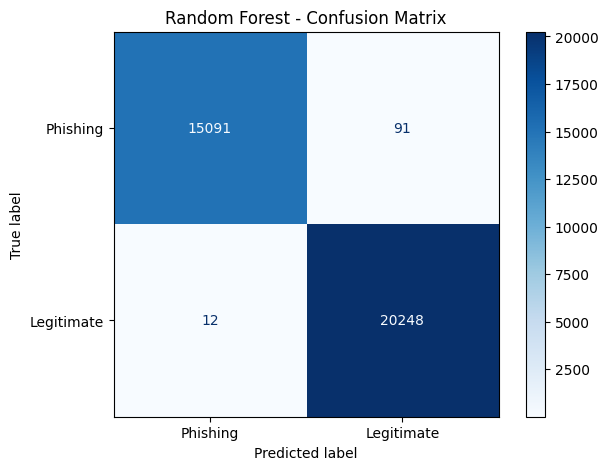

In [ ]:

# STEP 6.7: CONFUSION MATRIX

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Phishing", "Legitimate"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Random Forest - Confusion Matrix")
plt.show()


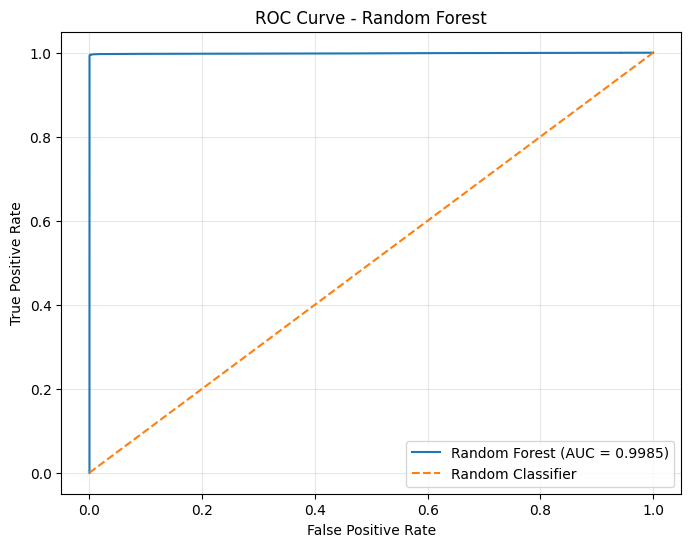

In [ ]:

# STEP 6.8: ROC CURVE

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_val_phishing,
    phishing_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# STEP 7.1: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training Logistic Regression...")

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Training Logistic Regression...
Logistic Regression training completed!


In [ ]:

# STEP 7.2: LOGISTIC REGRESSION VALIDATION

y_lr_pred = lr_model.predict(X_val)
y_lr_prob = lr_model.predict_proba(X_val)

lr_phishing_index = list(lr_model.classes_).index(0)
lr_phishing_prob = y_lr_prob[:, lr_phishing_index]

y_val_phishing = (y_val == 0).astype(int)

print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_val, y_lr_pred), 4))

print("Phishing Precision:",
      round(precision_score(y_val, y_lr_pred, pos_label=0), 4))

print("Phishing Recall:",
      round(recall_score(y_val, y_lr_pred, pos_label=0), 4))

print("Phishing F1 Score:",
      round(f1_score(y_val, y_lr_pred, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val_phishing, lr_phishing_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_lr_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))


LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy: 0.9963
Phishing Precision: 0.9996
Phishing Recall: 0.9918
Phishing F1 Score: 0.9957
ROC-AUC: 0.9984

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9996    0.9918    0.9957     15182
  Legitimate     0.9939    0.9997    0.9968     20260

    accuracy                         0.9963     35442
   macro avg     0.9967    0.9957    0.9962     35442
weighted avg     0.9963    0.9963    0.9963     35442



In [ ]:

# STEP 7.3: INSTALL XGBOOST

!pip -q install xgboost

print("XGBoost installed successfully!")


XGBoost installed successfully!


In [ ]:

# STEP 7.4: TRAIN XGBOOST

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("XGBoost training completed!")


Training XGBoost...
XGBoost training completed!


In [ ]:

# STEP 7.5: XGBOOST VALIDATION

y_xgb_pred = xgb_model.predict(X_val)
y_xgb_prob = xgb_model.predict_proba(X_val)

xgb_phishing_index = list(xgb_model.classes_).index(0)
xgb_phishing_prob = y_xgb_prob[:, xgb_phishing_index]

print("XGBOOST - VALIDATION RESULTS")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_val, y_xgb_pred), 4))

print("Phishing Precision:",
      round(precision_score(y_val, y_xgb_pred, pos_label=0), 4))

print("Phishing Recall:",
      round(recall_score(y_val, y_xgb_pred, pos_label=0), 4))

print("Phishing F1 Score:",
      round(f1_score(y_val, y_xgb_pred, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val_phishing, xgb_phishing_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_xgb_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))


XGBOOST - VALIDATION RESULTS
Accuracy: 0.9973
Phishing Precision: 0.9997
Phishing Recall: 0.9939
Phishing F1 Score: 0.9968
ROC-AUC: 0.9987

Classification Report:
              precision    recall  f1-score   support

    Phishing     0.9997    0.9939    0.9968     15182
  Legitimate     0.9955    0.9998    0.9976     20260

    accuracy                         0.9973     35442
   macro avg     0.9976    0.9969    0.9972     35442
weighted avg     0.9973    0.9973    0.9973     35442



In [ ]:

# STEP 8.1: MODEL COMPARISON

def evaluate_model(name, model, X_val, y_val):

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)

    phishing_index = list(model.classes_).index(0)
    phishing_probabilities = probabilities[:, phishing_index]

    actual_phishing = (y_val == 0).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            actual_phishing, phishing_probabilities
        )
    }


results = []

results.append(
    evaluate_model("Random Forest", rf_model, X_val, y_val)
)

results.append(
    evaluate_model("Logistic Regression", lr_model, X_val, y_val)
)

results.append(
    evaluate_model("XGBoost", xgb_model, X_val, y_val)
)

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    comparison_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.9973,0.9997,0.9939,0.9968,0.9987
0,Random Forest,0.9971,0.9992,0.9940,0.9966,0.9985
1,Logistic Regression,0.9963,0.9996,0.9918,0.9957,0.9984


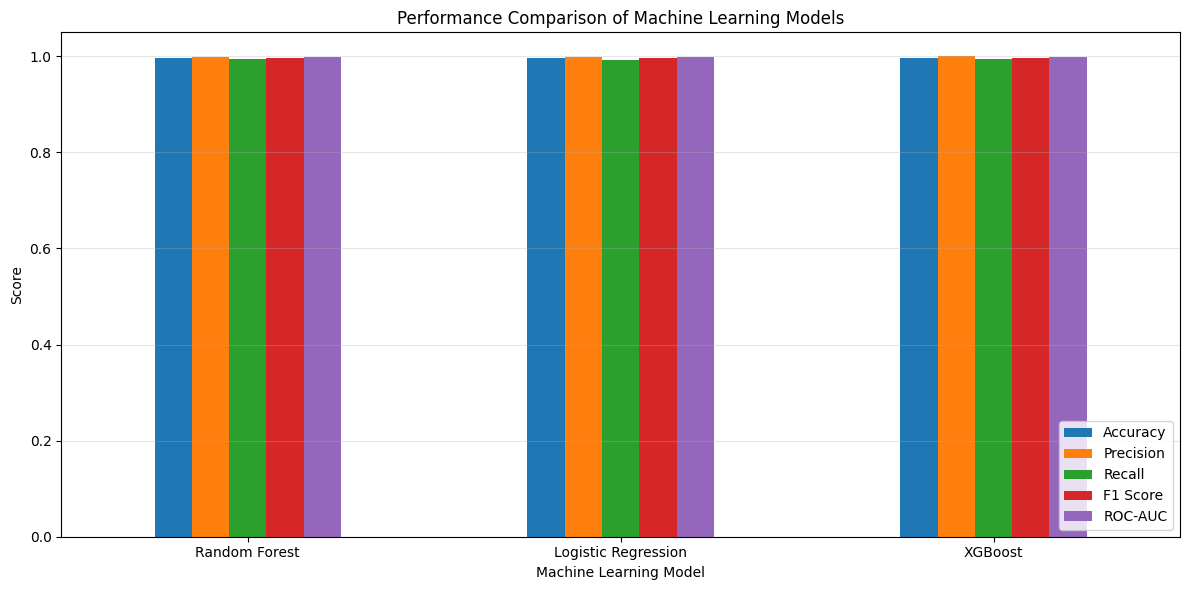

In [ ]:

# STEP 8.2: MODEL COMPARISON GRAPH

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_plot = comparison_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 8.3: SELECT BEST MODEL USING VALIDATION F1

model_objects = {
    "Random Forest": rf_model,
    "Logistic Regression": lr_model,
    "XGBoost": xgb_model
}

best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(),
    "Model"
]

best_model = model_objects[best_model_name]

print("Best model based on phishing F1-score:",
      best_model_name)

print("\nValidation performance:")
display(
    comparison_df[
        comparison_df["Model"] == best_model_name
    ].round(4)
)


Best model based on phishing F1-score: XGBoost

Validation performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.9973,0.9997,0.9939,0.9968,0.9987


In [ ]:

# STEP 9.1: FINAL TEST PREDICTIONS

y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)

test_phishing_index = list(best_model.classes_).index(0)
test_phishing_prob = y_test_prob[:, test_phishing_index]

y_test_phishing = (y_test == 0).astype(int)

print("FINAL TEST RESULTS")
print("=" * 50)

print("Selected Model:", best_model_name)

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Phishing Precision:",
      round(precision_score(y_test, y_test_pred, pos_label=0), 4))

print("Phishing Recall:",
      round(recall_score(y_test, y_test_pred, pos_label=0), 4))

print("Phishing F1 Score:",
      round(f1_score(y_test, y_test_pred, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test_phishing, test_phishing_prob), 4))


FINAL TEST RESULTS
Selected Model: XGBoost
Accuracy: 0.9966
Phishing Precision: 0.9989
Phishing Recall: 0.9931
Phishing F1 Score: 0.996
ROC-AUC: 0.9983


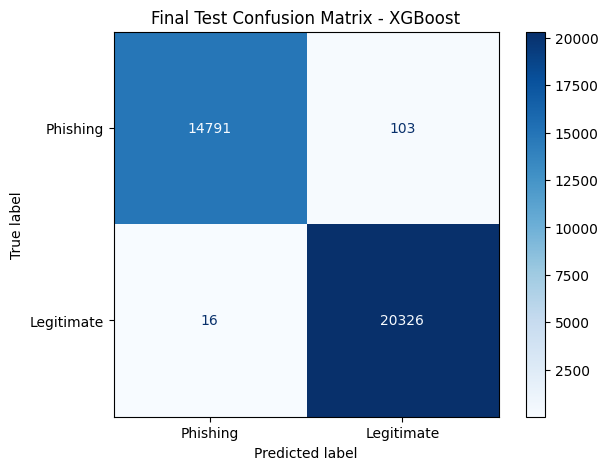

In [ ]:

# STEP 9.2: FINAL TEST CONFUSION MATRIX

test_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Phishing", "Legitimate"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.title(f"Final Test Confusion Matrix - {best_model_name}")
plt.show()


In [ ]:

# STEP 9.3: FINAL TEST CLASSIFICATION REPORT

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))


              precision    recall  f1-score   support

    Phishing     0.9989    0.9931    0.9960     14894
  Legitimate     0.9950    0.9992    0.9971     20342

    accuracy                         0.9966     35236
   macro avg     0.9969    0.9961    0.9965     35236
weighted avg     0.9966    0.9966    0.9966     35236



In [ ]:
#SHAP
!pip -q install shap


import shap
import numpy as np
import matplotlib.pyplot as plt

print("SHAP imported successfully!")
print("SHAP version:", shap.__version__)

SHAP imported successfully!
SHAP version: 0.54.1


In [ ]:
# Select 500 test samples
X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Background dataset for explanations
X_background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

print("SHAP test samples:", X_shap.shape)
print("Background samples:", X_background.shape)

SHAP test samples: (500, 18)
Background samples: (100, 18)


In [ ]:
# Identify the phishing class
phishing_index = list(best_model.classes_).index(0)

if best_model_name in ["Random Forest", "XGBoost"]:

    # Tree-based SHAP explainer
    explainer = shap.TreeExplainer(best_model)
    shap_output = explainer(X_shap)

else:

    # Model-agnostic explainer for Logistic Regression pipeline
    explainer = shap.Explainer(
        best_model.predict_proba,
        X_background
    )

    shap_output = explainer(X_shap)

# Extract SHAP values
values = shap_output.values

# Select the SHAP values corresponding to phishing (label 0)
if isinstance(values, list):
    phishing_shap_values = values[phishing_index]

elif values.ndim == 3:
    phishing_shap_values = values[:, :, phishing_index]

else:
    phishing_shap_values = values

print("SHAP calculation completed!")
print("SHAP values shape:", phishing_shap_values.shape)

SHAP calculation completed!
SHAP values shape: (500, 18)


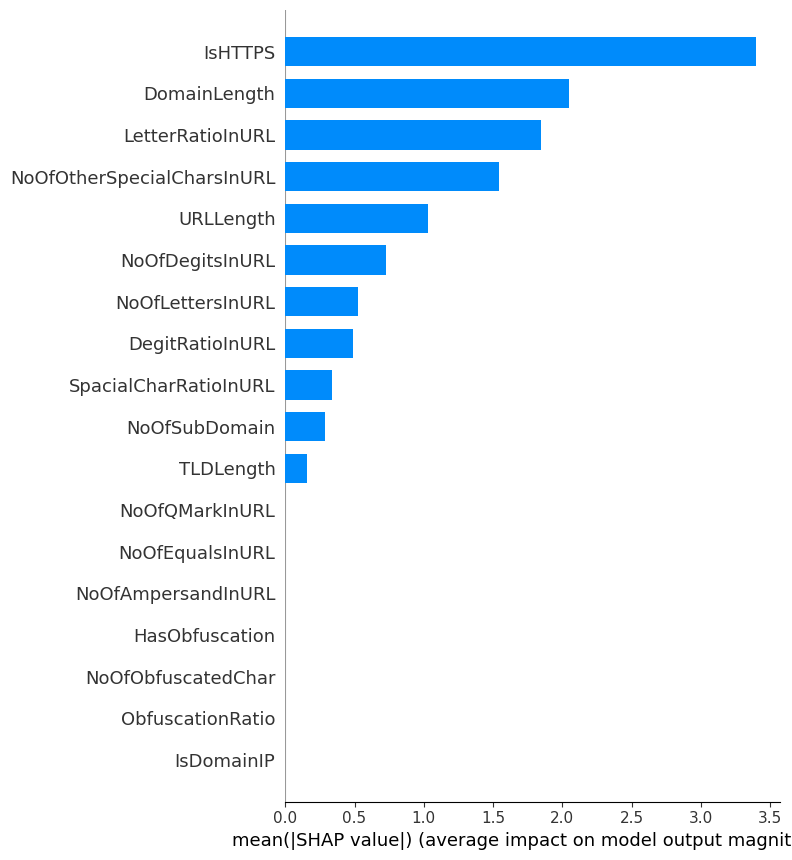

In [ ]:
shap.summary_plot(
    phishing_shap_values,
    X_shap,
    plot_type="bar",
    max_display=18
)

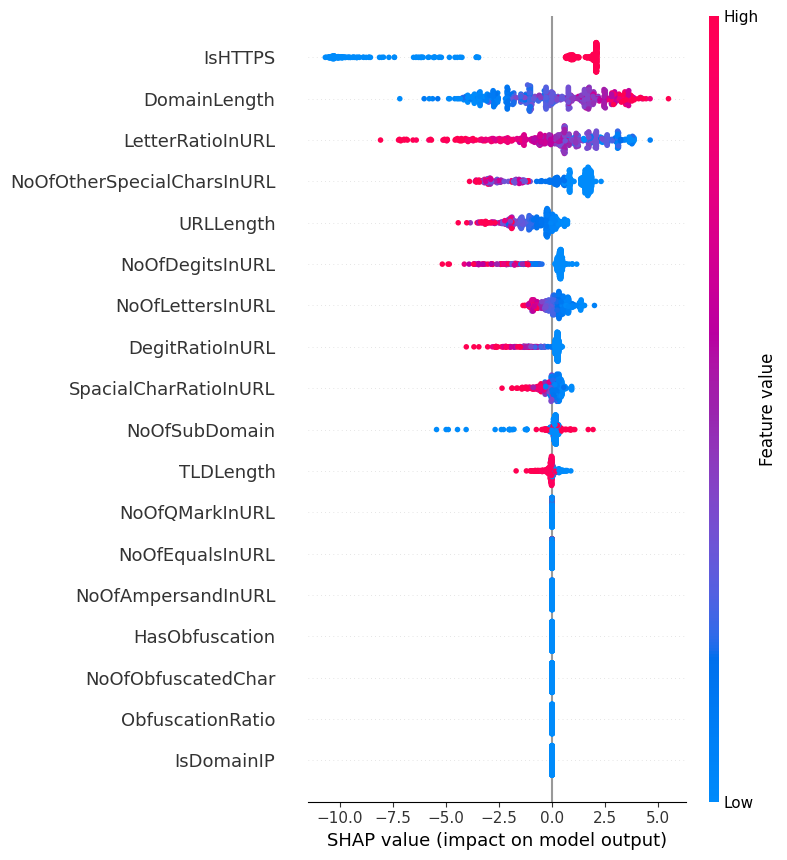

In [ ]:
shap.summary_plot(
    phishing_shap_values,
    X_shap,
    max_display=18
)

Predicted Class: Phishing
Phishing Probability: 99.99 %


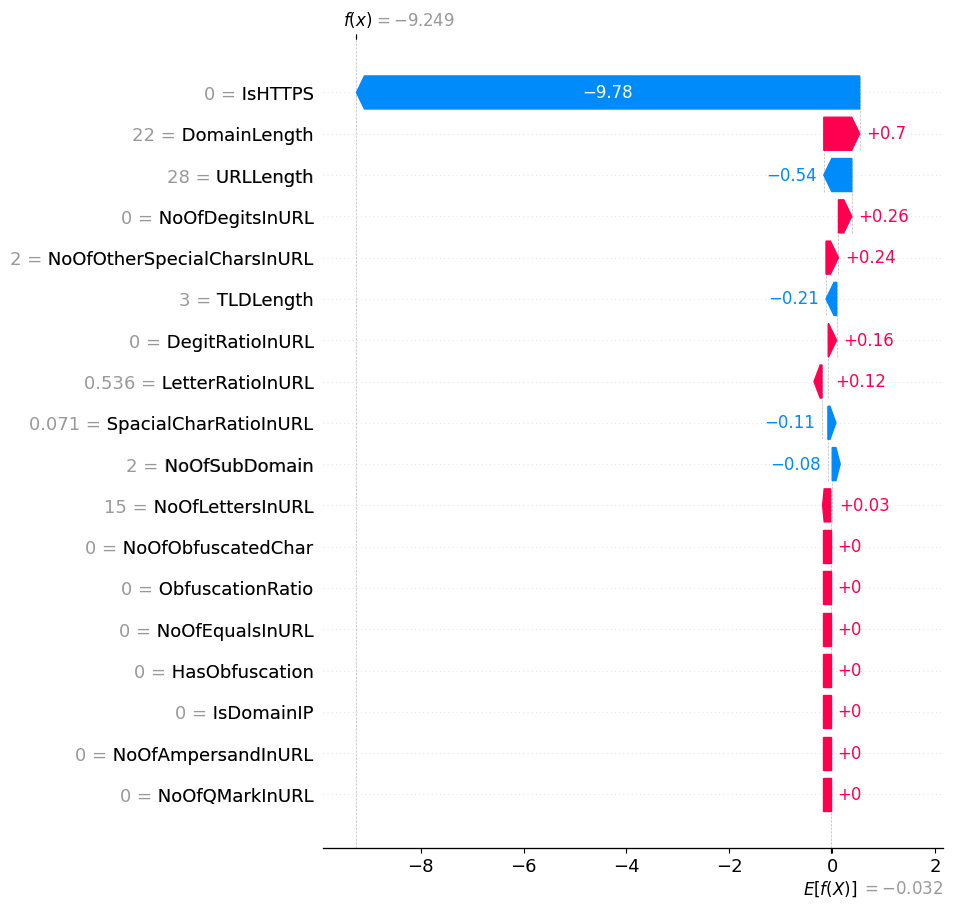

In [ ]:
# Select one URL sample
sample_index = 0

single_url = X_shap.iloc[[sample_index]]

# Calculate prediction
prediction = best_model.predict(single_url)[0]

# Calculate phishing probability
probabilities = best_model.predict_proba(single_url)[0]
phishing_probability = probabilities[phishing_index]

print("Predicted Class:",
      "Phishing" if prediction == 0 else "Legitimate")

print("Phishing Probability:",
      round(phishing_probability * 100, 2), "%")

# SHAP waterfall plot
single_explanation = shap.Explanation(
    values=phishing_shap_values[sample_index],
    base_values=shap_output.base_values[sample_index]
        if np.asarray(shap_output.base_values).ndim == 1
        else shap_output.base_values[sample_index][phishing_index],
    data=X_shap.iloc[sample_index].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(single_explanation, max_display=18)

In [ ]:
import pandas as pd

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_SHAP_Importance": np.abs(
        phishing_shap_values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
)

display(shap_importance)

shap_importance.to_csv(
    "shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully!")

,Feature,Mean_SHAP_Importance
17,IsHTTPS,3.397407
1,DomainLength,2.050757
9,LetterRatioInURL,1.847996
15,NoOfOtherSpecialCharsInURL,1.540450
0,URLLength,1.029393
10,NoOfDegitsInURL,0.727665
8,NoOfLettersInURL,0.523579
11,DegitRatioInURL,0.485697
16,SpacialCharRatioInURL,0.337612
4,NoOfSubDomain,0.288377


SHAP feature importance saved successfully!


In [ ]:
#PYVIS
!pip -q install pyvis
from pyvis.network import Network
from IPython.display import display, IFrame
import pandas as pd
import numpy as np
import os

In [ ]:
sample_index = 0

single_url = X_shap.iloc[[sample_index]]

prediction = best_model.predict(single_url)[0]

probabilities = best_model.predict_proba(single_url)[0]
phishing_probability = probabilities[phishing_index]

prediction_label = (
    "Phishing" if prediction == 0 else "Legitimate"
)

print("Prediction:", prediction_label)
print("Phishing Probability:",
      round(phishing_probability * 100, 2), "%")

Prediction: Phishing
Phishing Probability: 99.99 %


In [ ]:
original_url = df_clean.iloc[X_shap.index[sample_index]]["URL"]

print("Input URL:", original_url)

Input URL: http://www.argus.beeppool.org


In [ ]:
# Get SHAP values for the selected URL
sample_shap_values = phishing_shap_values[sample_index]

# Create a feature explanation table
feature_explanations = pd.DataFrame({
    "Feature": X_shap.columns,
    "Feature_Value": X_shap.iloc[sample_index].values,
    "SHAP_Value": sample_shap_values
})

feature_explanations["Absolute_SHAP"] = (
    feature_explanations["SHAP_Value"].abs()
)

# Select the six most influential features
top_features = feature_explanations.sort_values(
    by="Absolute_SHAP",
    ascending=False
).head(6)

display(top_features)

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
17,IsHTTPS,0.0,-9.782141,9.782141
1,DomainLength,22.0,0.697577,0.697577
0,URLLength,28.0,-0.543735,0.543735
10,NoOfDegitsInURL,0.0,0.259096,0.259096
15,NoOfOtherSpecialCharsInURL,2.0,0.241647,0.241647
3,TLDLength,3.0,-0.206381,0.206381


In [ ]:
# Create an interactive network
net = Network(
    height="750px",
    width="100%",
    directed=True,
    bgcolor="#ffffff",
    font_color="#222222"
)

net.barnes_hut()

# Main URL node
net.add_node(
    "url",
    label="Input URL",
    title=str(original_url),
    color="#8ecae6",
    shape="box",
    size=30
)

# Prediction node
prediction_color = (
    "#ef476f" if prediction == 0 else "#06d6a0"
)

net.add_node(
    "prediction",
    label=prediction_label,
    title=(
        f"Prediction: {prediction_label}\n"
        f"Phishing probability: "
        f"{phishing_probability * 100:.2f}%"
    ),
    color=prediction_color,
    shape="star",
    size=35
)

# Connect URL to prediction
net.add_edge(
    "url",
    "prediction",
    label="ML prediction",
    color="#777777"
)

# Add the six most influential feature nodes
for i, row in enumerate(top_features.itertuples(), start=1):

    feature_id = f"feature_{i}"

    shap_value = float(row.SHAP_Value)
    feature_value = row.Feature_Value

    if shap_value > 0:
        direction = "Pushes towards phishing"
        node_color = "#ffadad"
    else:
        direction = "Pushes away from phishing"
        node_color = "#b7e4c7"

    tooltip = (
        f"Feature: {row.Feature}\n"
        f"Value: {feature_value}\n"
        f"SHAP value: {shap_value:.5f}\n"
        f"Interpretation: {direction}"
    )

    net.add_node(
        feature_id,
        label=str(row.Feature),
        title=tooltip,
        color=node_color,
        shape="ellipse",
        size=22
    )

    net.add_edge(
        "url",
        feature_id,
        label="Feature",
        color="#999999"
    )

    net.add_edge(
        feature_id,
        "prediction",
        label=f"SHAP: {shap_value:.4f}",
        color="#777777"
    )

# Save the graph
graph_file = "phishing_explanation_graph.html"

net.write_html(graph_file)

print("Interactive graph created successfully!")
print("File:", graph_file)

Interactive graph created successfully!
File: phishing_explanation_graph.html


In [ ]:
display(
    IFrame(
        src=graph_file,
        width="100%",
        height=750
    )
)

In [ ]:
from google.colab import files

files.download("phishing_explanation_graph.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd

# Select test samples
X_robust = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
).copy()

y_robust = y_test.loc[X_robust.index].copy()

print("Robustness test samples:", X_robust.shape)
print("Actual labels:", y_robust.shape)

Robustness test samples: (2000, 18)
Actual labels: (2000,)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline_predictions = best_model.predict(X_robust)

baseline_results = {
    "Perturbation": "Original",
    "Accuracy": accuracy_score(
        y_robust, baseline_predictions
    ),
    "Phishing Precision": precision_score(
        y_robust, baseline_predictions,
        pos_label=0, zero_division=0
    ),
    "Phishing Recall": recall_score(
        y_robust, baseline_predictions,
        pos_label=0, zero_division=0
    ),
    "Phishing F1": f1_score(
        y_robust, baseline_predictions,
        pos_label=0, zero_division=0
    )
}

print(pd.Series(baseline_results))

Perturbation          Original
Accuracy                 0.997
Phishing Precision    0.998802
Phishing Recall       0.994041
Phishing F1           0.996416
dtype: object


In [ ]:
binary_features = [
    "IsDomainIP",
    "HasObfuscation",
    "IsHTTPS"
]

# Features eligible for perturbation
perturbable_features = [
    col for col in X_robust.columns
    if col not in binary_features
]

print("Features being perturbed:")
print(perturbable_features)

print("\nBinary features kept unchanged:")
print(binary_features)

Features being perturbed:
['URLLength', 'DomainLength', 'TLDLength', 'NoOfSubDomain', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL']

Binary features kept unchanged:
['IsDomainIP', 'HasObfuscation', 'IsHTTPS']


In [ ]:
# Identify count/length features that should remain integers
integer_features = [
    "URLLength",
    "DomainLength",
    "TLDLength",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL"
]

# Ratio features must remain between 0 and 1
ratio_features = [
    "ObfuscationRatio",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "SpacialCharRatioInURL"
]

def create_perturbed_data(data, perturbation_level):

    perturbed = data.copy()
    rng = np.random.default_rng(42)

    for feature in perturbable_features:

        # Use training data range
        feature_range = (
            X_train[feature].max() - X_train[feature].min()
        )

        # Generate random changes
        noise = rng.uniform(
            -perturbation_level,
            perturbation_level,
            size=len(data)
        ) * feature_range

        perturbed[feature] = (
            perturbed[feature].to_numpy() + noise
        )

        # Keep values within training data limits
        perturbed[feature] = perturbed[feature].clip(
            lower=X_train[feature].min(),
            upper=X_train[feature].max()
        )

        # Maintain integer values for count and length features
        if feature in integer_features:
            perturbed[feature] = perturbed[feature].round()

        # Maintain valid ratio ranges
        if feature in ratio_features:
            perturbed[feature] = perturbed[feature].clip(0, 1)

    return perturbed


print("Perturbation function created successfully!")

Perturbation function created successfully!


In [ ]:
robustness_results = [baseline_results]

levels = [0.05, 0.10, 0.20]

for level in levels:

    X_perturbed = create_perturbed_data(
        X_robust,
        level
    )

    predictions = best_model.predict(X_perturbed)

    result = {
        "Perturbation": f"{int(level * 100)}%",
        "Accuracy": accuracy_score(
            y_robust, predictions
        ),
        "Phishing Precision": precision_score(
            y_robust, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_robust, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_robust, predictions,
            pos_label=0, zero_division=0
        )
    }

    robustness_results.append(result)

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df.round(4))

,Perturbation,Accuracy,Phishing Precision,Phishing Recall,Phishing F1
0,Original,0.9970,0.9988,0.9940,0.9964
1,5%,0.5775,0.4981,0.9571,0.6552
2,10%,0.5440,0.4781,0.9487,0.6358
3,20%,0.5400,0.4756,0.9428,0.6323


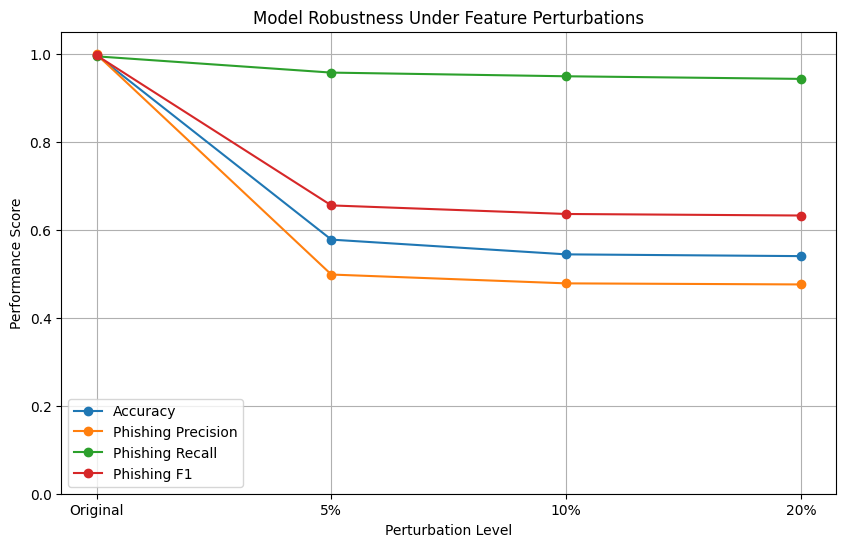

In [ ]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Phishing Precision",
    "Phishing Recall",
    "Phishing F1"
]

plt.figure(figsize=(10, 6))

for metric in metrics:
    plt.plot(
        robustness_df["Perturbation"],
        robustness_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Perturbation Level")
plt.ylabel("Performance Score")
plt.title("Model Robustness Under Feature Perturbations")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
baseline_accuracy = robustness_df.loc[
    robustness_df["Perturbation"] == "Original",
    "Accuracy"
].iloc[0]

robustness_df["Accuracy Drop (%)"] = (
    (baseline_accuracy - robustness_df["Accuracy"])
    / baseline_accuracy
) * 100

display(robustness_df.round(4))

robustness_df.to_csv(
    "robustness_results.csv",
    index=False
)

print("Robustness results saved successfully!")

,Perturbation,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,Accuracy Drop (%)
0,Original,0.9970,0.9988,0.9940,0.9964,0.0000
1,5%,0.5775,0.4981,0.9571,0.6552,42.0762
2,10%,0.5440,0.4781,0.9487,0.6358,45.4363
3,20%,0.5400,0.4756,0.9428,0.6323,45.8375


Robustness results saved successfully!


In [ ]:
# Display all selected feature names and their data types

for feature in url_features:
    print(feature, ":", df[feature].dtype)

URLLength : int64
DomainLength : int64
IsDomainIP : int64
TLDLength : int64
NoOfSubDomain : int64
HasObfuscation : int64
NoOfObfuscatedChar : int64
ObfuscationRatio : float64
NoOfLettersInURL : int64
LetterRatioInURL : float64
NoOfDegitsInURL : int64
DegitRatioInURL : float64
NoOfEqualsInURL : int64
NoOfQMarkInURL : int64
NoOfAmpersandInURL : int64
NoOfOtherSpecialCharsInURL : int64
SpacialCharRatioInURL : float64
IsHTTPS : int64


In [ ]:
# Display 10 actual URLs and their corresponding 18 features

display(
    df[["URL"] + url_features].head(10)
)

,URL,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,https://www.southbankmosaics.com,31,24,0,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1
1,https://www.uni-mainz.de,23,16,0,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1
2,https://www.voicefmradio.co.uk,29,22,0,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1
3,https://www.sfnmjournal.com,26,19,0,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1
4,https://www.rewildingargentina.org,33,26,0,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1
5,https://www.globalreporting.org,30,23,0,3,1,0,0,0.0,17,0.567,0,0.0,0,0,0,1,0.033,1
6,https://www.saffronart.com,25,18,0,3,1,0,0,0.0,12,0.480,0,0.0,0,0,0,1,0.040,1
7,https://www.nerdscandy.com,25,18,0,3,1,0,0,0.0,12,0.480,0,0.0,0,0,0,1,0.040,1
8,https://www.hyderabadonline.in,29,22,0,2,1,0,0,0.0,16,0.552,0,0.0,0,0,0,1,0.034,1
9,https://www.aap.org,18,11,0,3,1,0,0,0.0,5,0.278,0,0.0,0,0,0,1,0.056,1


In [ ]:
#verifying formula
from urllib.parse import urlsplit
import ipaddress
import pandas as pd
import re

def extract_basic_features(url):

    parsed = urlsplit(url)
    host = parsed.hostname or ""

    try:
        ipaddress.ip_address(host)
        is_ip = 1
    except ValueError:
        is_ip = 0

    tld = host.rsplit(".", 1)[-1] if "." in host else ""

    url_length = len(url)
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    return {
        "URLLength": url_length,
        "DomainLength": len(host),
        "IsDomainIP": is_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": max(host.count(".") - 1, 0),
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / url_length if url_length else 0,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / url_length if url_length else 0,
        "NoOfEqualsInURL": url.count("="),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfAmpersandInURL": url.count("&"),
        "IsHTTPS": int(parsed.scheme.lower() == "https")
    }


# Compare the first 10 dataset records
comparison_rows = []

for _, row in df_clean.head(10).iterrows():

    calculated = extract_basic_features(row["URL"])

    for feature, calculated_value in calculated.items():

        comparison_rows.append({
            "URL": row["URL"],
            "Feature": feature,
            "Dataset_Value": row[feature],
            "Calculated_Value": calculated_value,
            "Match": abs(
                float(row[feature]) - float(calculated_value)
            ) < 0.001
        })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,URL,Feature,Dataset_Value,Calculated_Value,Match
0,https://www.southbankmosaics.com,URLLength,31.0,32.0,False
1,https://www.southbankmosaics.com,DomainLength,24.0,24.0,True
2,https://www.southbankmosaics.com,IsDomainIP,0.0,0.0,True
3,https://www.southbankmosaics.com,TLDLength,3.0,3.0,True
4,https://www.southbankmosaics.com,NoOfSubDomain,1.0,1.0,True
...,...,...,...,...,...
125,https://www.aap.org,DegitRatioInURL,0.0,0.0,True
126,https://www.aap.org,NoOfEqualsInURL,0.0,0.0,True
127,https://www.aap.org,NoOfQMarkInURL,0.0,0.0,True
128,https://www.aap.org,NoOfAmpersandInURL,0.0,0.0,True


In [ ]:
print("Total comparisons:", len(comparison_df))

print(
    "Matching comparisons:",
    comparison_df["Match"].sum()
)

print(
    "Mismatching comparisons:",
    (~comparison_df["Match"]).sum()
)

print("\nMismatches:")
display(
    comparison_df[comparison_df["Match"] == False]
)

Total comparisons: 130
Matching comparisons: 100
Mismatching comparisons: 30

Mismatches:


,URL,Feature,Dataset_Value,Calculated_Value,Match
0,https://www.southbankmosaics.com,URLLength,31.000,32.000000,False
5,https://www.southbankmosaics.com,NoOfLettersInURL,18.000,27.000000,False
6,https://www.southbankmosaics.com,LetterRatioInURL,0.581,0.843750,False
13,https://www.uni-mainz.de,URLLength,23.000,24.000000,False
18,https://www.uni-mainz.de,NoOfLettersInURL,9.000,18.000000,False
19,https://www.uni-mainz.de,LetterRatioInURL,0.391,0.750000,False
26,https://www.voicefmradio.co.uk,URLLength,29.000,30.000000,False
31,https://www.voicefmradio.co.uk,NoOfLettersInURL,15.000,24.000000,False
32,https://www.voicefmradio.co.uk,LetterRatioInURL,0.517,0.800000,False
39,https://www.sfnmjournal.com,URLLength,26.000,27.000000,False


In [ ]:
#13.3
for i in range(3):

    url = df_clean.iloc[i]["URL"]

    print("\nURL:", repr(url))
    print("Python length:", len(url))
    print("Dataset URLLength:",
          df_clean.iloc[i]["URLLength"])

    print("Characters:")
    for position, character in enumerate(url):
        print(position, repr(character))


URL: 'https://www.southbankmosaics.com'
Python length: 32
Dataset URLLength: 31
Characters:
0 'h'
1 't'
2 't'
3 'p'
4 's'
5 ':'
6 '/'
7 '/'
8 'w'
9 'w'
10 'w'
11 '.'
12 's'
13 'o'
14 'u'
15 't'
16 'h'
17 'b'
18 'a'
19 'n'
20 'k'
21 'm'
22 'o'
23 's'
24 'a'
25 'i'
26 'c'
27 's'
28 '.'
29 'c'
30 'o'
31 'm'

URL: 'https://www.uni-mainz.de'
Python length: 24
Dataset URLLength: 23
Characters:
0 'h'
1 't'
2 't'
3 'p'
4 's'
5 ':'
6 '/'
7 '/'
8 'w'
9 'w'
10 'w'
11 '.'
12 'u'
13 'n'
14 'i'
15 '-'
16 'm'
17 'a'
18 'i'
19 'n'
20 'z'
21 '.'
22 'd'
23 'e'

URL: 'https://www.voicefmradio.co.uk'
Python length: 30
Dataset URLLength: 29
Characters:
0 'h'
1 't'
2 't'
3 'p'
4 's'
5 ':'
6 '/'
7 '/'
8 'w'
9 'w'
10 'w'
11 '.'
12 'v'
13 'o'
14 'i'
15 'c'
16 'e'
17 'f'
18 'm'
19 'r'
20 'a'
21 'd'
22 'i'
23 'o'
24 '.'
25 'c'
26 'o'
27 '.'
28 'u'
29 'k'


In [ ]:
#13.4
url = df_clean.iloc[0]["URL"]

print("Original URL:", url)

print("Total letters:", sum(c.isalpha() for c in url))

print("Letters in URL after removing protocol:",
      sum(c.isalpha() for c in url.split("://")[-1]))

print("Letters in hostname:",
      sum(c.isalpha() for c in urlsplit(url).hostname or ""))

print("Dataset NoOfLettersInURL:",
      df_clean.iloc[0]["NoOfLettersInURL"])

Original URL: https://www.southbankmosaics.com
Total letters: 27
Letters in URL after removing protocol: 22
Letters in hostname: 22
Dataset NoOfLettersInURL: 18


In [ ]:
#13.5
row = df_clean.iloc[0]

print("Dataset LetterRatioInURL:",
      row["LetterRatioInURL"])

print("Dataset ratio × URLLength:",
      row["LetterRatioInURL"] * row["URLLength"])

print("Dataset letter count:",
      row["NoOfLettersInURL"])

Dataset LetterRatioInURL: 0.581
Dataset ratio × URLLength: 18.011
Dataset letter count: 18


In [ ]:
#13.6
def test_url_conventions(url):

    # Remove common protocol and www prefix
    cleaned = re.sub(r"^https?://www\.", "", url)

    # Candidate substring
    candidate = cleaned[:-1]

    return {
        "Original_Length": len(url),
        "Length_Minus_1": len(url) - 1,

        "Letters_Original": sum(c.isalpha() for c in url),

        "Letters_Without_Protocol": sum(
            c.isalpha() for c in url.split("://")[-1]
        ),

        "Letters_Without_Protocol_WWW": sum(
            c.isalpha() for c in cleaned
        ),

        "Letters_Candidate_Substring": sum(
            c.isalpha() for c in candidate
        ),

        "Candidate_Substring": candidate
    }


for i in range(10):

    row = df_clean.iloc[i]

    print("\nURL:", row["URL"])

    print("Dataset URLLength:", row["URLLength"])
    print("Dataset Letters:", row["NoOfLettersInURL"])

    print(test_url_conventions(row["URL"]))


URL: https://www.southbankmosaics.com
Dataset URLLength: 31
Dataset Letters: 18
{'Original_Length': 32, 'Length_Minus_1': 31, 'Letters_Original': 27, 'Letters_Without_Protocol': 22, 'Letters_Without_Protocol_WWW': 19, 'Letters_Candidate_Substring': 18, 'Candidate_Substring': 'southbankmosaics.co'}

URL: https://www.uni-mainz.de
Dataset URLLength: 23
Dataset Letters: 9
{'Original_Length': 24, 'Length_Minus_1': 23, 'Letters_Original': 18, 'Letters_Without_Protocol': 13, 'Letters_Without_Protocol_WWW': 10, 'Letters_Candidate_Substring': 9, 'Candidate_Substring': 'uni-mainz.d'}

URL: https://www.voicefmradio.co.uk
Dataset URLLength: 29
Dataset Letters: 15
{'Original_Length': 30, 'Length_Minus_1': 29, 'Letters_Original': 24, 'Letters_Without_Protocol': 19, 'Letters_Without_Protocol_WWW': 16, 'Letters_Candidate_Substring': 15, 'Candidate_Substring': 'voicefmradio.co.u'}

URL: https://www.sfnmjournal.com
Dataset URLLength: 26
Dataset Letters: 13
{'Original_Length': 27, 'Length_Minus_1': 26, 

In [ ]:
#13.7
test_rows = df_clean.head(1000)

matches = []

for _, row in test_rows.iterrows():

    url = row["URL"]

    cleaned = re.sub(r"^https?://www\.", "", url)
    candidate = cleaned[:-1]

    calculated_length = len(url) - 1

    calculated_letters = sum(
        c.isalpha() for c in candidate
    )

    matches.append({
        "URLLength_Match":
            calculated_length == row["URLLength"],

        "Letters_Match":
            calculated_letters == row["NoOfLettersInURL"]
    })

audit_df = pd.DataFrame(matches)

print("URLLength matching:",
      audit_df["URLLength_Match"].mean() * 100, "%")

print("Letter count matching:",
      audit_df["Letters_Match"].mean() * 100, "%")

URLLength matching: 91.10000000000001 %
Letter count matching: 81.5 %


In [ ]:
import re
import pandas as pd

test_rows = df_clean.head(1000).copy()

audit = []

for idx, row in test_rows.iterrows():
    url = row["URL"]

    cleaned = re.sub(r"^https?://www\.", "", url)
    candidate = cleaned[:-1]

    calculated_length = len(url) - 1
    calculated_letters = sum(c.isalpha() for c in candidate)

    if calculated_length != row["URLLength"] or calculated_letters != row["NoOfLettersInURL"]:
        audit.append({
            "URL": url,
            "Dataset_URLLength": row["URLLength"],
            "Calculated_URLLength": calculated_length,
            "Dataset_Letters": row["NoOfLettersInURL"],
            "Calculated_Letters": calculated_letters
        })

mismatch_df = pd.DataFrame(audit)

print("Total mismatches:", len(mismatch_df))
display(mismatch_df.head(20))

Total mismatches: 191


,URL,Dataset_URLLength,Calculated_URLLength,Dataset_Letters,Calculated_Letters
0,http://www.shprakserf.gq,24,23,12,11
1,https://service-mitld.firebaseapp.com/,37,37,26,31
2,https://liuy-9a930.web.app/,26,26,11,16
3,https://ipfs.io/ipfs/qmrvvyr84esa2assw9vvwupqj...,91,91,69,74
4,http://att-103731-107123.weeblysite.com/,40,39,16,20
5,https://hidok4f8zl.firebaseapp.com/,35,34,22,27
6,https://mechinchem-5cb8a.web.app/,32,32,19,24
7,https://fb-restriction-case-97be5.web.app/,41,41,25,30
8,https://pontosapontamentolu.com/gclid/=/c/?gcl...,140,139,99,103
9,https://dev-634536.pantheonsite.io/,34,34,17,22


In [ ]:
import re
import pandas as pd

test_rows = df_clean.head(1000).copy()

audit = []

for _, row in test_rows.iterrows():

    url = row["URL"]

    # Remove protocol
    without_protocol = re.sub(
        r"^https?://",
        "",
        url,
        flags=re.IGNORECASE
    )

    # Remove www. if present
    without_www = re.sub(
        r"^www\.",
        "",
        without_protocol,
        flags=re.IGNORECASE
    )

    # Candidate URL lengths
    length_original = len(url)
    length_without_trailing_slash = len(url.rstrip("/"))

    # Candidate letter count
    letter_count = sum(c.isalpha() for c in without_www)

    audit.append({
        "URLLength_Original_Match":
            length_original == row["URLLength"],

        "URLLength_NoSlash_Match":
            length_without_trailing_slash == row["URLLength"],

        "LetterCount_Match":
            letter_count == row["NoOfLettersInURL"]
    })

audit_df = pd.DataFrame(audit)

print("Original length match:",
      audit_df["URLLength_Original_Match"].mean() * 100, "%")

print("Length without trailing slash match:",
      audit_df["URLLength_NoSlash_Match"].mean() * 100, "%")

print("Corrected letter count match:",
      audit_df["LetterCount_Match"].mean() * 100, "%")

Original length match: 8.9 %
Length without trailing slash match: 10.7 %
Corrected letter count match: 15.9 %


In [ ]:
import re
import pandas as pd
from urllib.parse import urlsplit

def inspect_url(url):

    parsed = urlsplit(url)

    candidates = {
        "Original": url,
        "Without_protocol": re.sub(
            r"^https?://", "", url, flags=re.I
        ),
        "Without_protocol_www": re.sub(
            r"^https?://(www\.)?", "", url, flags=re.I
        ),
        "Hostname": parsed.hostname or "",
        "Hostname_without_www": re.sub(
            r"^www\.", "", parsed.hostname or "", flags=re.I
        ),
        "Without_protocol_and_slash": re.sub(
            r"^https?://", "", url, flags=re.I
        ).rstrip("/")
    }

    results = []

    for name, value in candidates.items():
        results.append({
            "Representation": name,
            "Value": value,
            "Length": len(value),
            "Letters": sum(c.isalpha() for c in value),
            "Digits": sum(c.isdigit() for c in value),
            "Special_chars": sum(not c.isalnum() for c in value)
        })

    return pd.DataFrame(results)


for i in [0, 1, 2, 3, 4]:
    row = df_clean.iloc[i]

    print("\n" + "=" * 70)
    print("URL:", row["URL"])
    print("Dataset URLLength:", row["URLLength"])
    print("Dataset letters:", row["NoOfLettersInURL"])
    print("Dataset digits:", row["NoOfDegitsInURL"])
    print("Dataset other special chars:",
          row["NoOfOtherSpecialCharsInURL"])

    display(inspect_url(row["URL"]))


URL: https://www.southbankmosaics.com
Dataset URLLength: 31
Dataset letters: 18
Dataset digits: 0
Dataset other special chars: 1


,Representation,Value,Length,Letters,Digits,Special_chars
0,Original,https://www.southbankmosaics.com,32,27,0,5
1,Without_protocol,www.southbankmosaics.com,24,22,0,2
2,Without_protocol_www,southbankmosaics.com,20,19,0,1
3,Hostname,www.southbankmosaics.com,24,22,0,2
4,Hostname_without_www,southbankmosaics.com,20,19,0,1
5,Without_protocol_and_slash,www.southbankmosaics.com,24,22,0,2



URL: https://www.uni-mainz.de
Dataset URLLength: 23
Dataset letters: 9
Dataset digits: 0
Dataset other special chars: 2


,Representation,Value,Length,Letters,Digits,Special_chars
0,Original,https://www.uni-mainz.de,24,18,0,6
1,Without_protocol,www.uni-mainz.de,16,13,0,3
2,Without_protocol_www,uni-mainz.de,12,10,0,2
3,Hostname,www.uni-mainz.de,16,13,0,3
4,Hostname_without_www,uni-mainz.de,12,10,0,2
5,Without_protocol_and_slash,www.uni-mainz.de,16,13,0,3



URL: https://www.voicefmradio.co.uk
Dataset URLLength: 29
Dataset letters: 15
Dataset digits: 0
Dataset other special chars: 2


,Representation,Value,Length,Letters,Digits,Special_chars
0,Original,https://www.voicefmradio.co.uk,30,24,0,6
1,Without_protocol,www.voicefmradio.co.uk,22,19,0,3
2,Without_protocol_www,voicefmradio.co.uk,18,16,0,2
3,Hostname,www.voicefmradio.co.uk,22,19,0,3
4,Hostname_without_www,voicefmradio.co.uk,18,16,0,2
5,Without_protocol_and_slash,www.voicefmradio.co.uk,22,19,0,3



URL: https://www.sfnmjournal.com
Dataset URLLength: 26
Dataset letters: 13
Dataset digits: 0
Dataset other special chars: 1


,Representation,Value,Length,Letters,Digits,Special_chars
0,Original,https://www.sfnmjournal.com,27,22,0,5
1,Without_protocol,www.sfnmjournal.com,19,17,0,2
2,Without_protocol_www,sfnmjournal.com,15,14,0,1
3,Hostname,www.sfnmjournal.com,19,17,0,2
4,Hostname_without_www,sfnmjournal.com,15,14,0,1
5,Without_protocol_and_slash,www.sfnmjournal.com,19,17,0,2



URL: https://www.rewildingargentina.org
Dataset URLLength: 33
Dataset letters: 20
Dataset digits: 0
Dataset other special chars: 1


,Representation,Value,Length,Letters,Digits,Special_chars
0,Original,https://www.rewildingargentina.org,34,29,0,5
1,Without_protocol,www.rewildingargentina.org,26,24,0,2
2,Without_protocol_www,rewildingargentina.org,22,21,0,1
3,Hostname,www.rewildingargentina.org,26,24,0,2
4,Hostname_without_www,rewildingargentina.org,22,21,0,1
5,Without_protocol_and_slash,www.rewildingargentina.org,26,24,0,2


In [ ]:
print("Selected model:", best_model_name)
print("Model object:", type(best_model))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFeatures:")
print(list(X_train.columns))

Selected model: XGBoost
Model object: <class 'xgboost.sklearn.XGBClassifier'>

Training data shape: (164692, 18)
Testing data shape: (35236, 18)

Features:
['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']


In [ ]:

import re
import ipaddress
import numpy as np
import pandas as pd
from urllib.parse import urlsplit

def extract_url_features(url):

    url = str(url).strip()

    # Add a scheme if the user does not provide one
    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "http://" + url

    parsed = urlsplit(url)
    hostname = parsed.hostname or ""

    # Basic URL components
    url_length = len(url)
    domain_length = len(hostname)

    # Check whether the hostname is an IP address
    try:
        ipaddress.ip_address(hostname)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    # Domain labels
    labels = hostname.lower().split(".")
    tld = labels[-1] if len(labels) > 1 else ""

    no_of_subdomain = max(0, len(labels) - 2)

    # Character counts
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    encoded_chars = re.findall(r"%[0-9a-fA-F]{2}", url)

    equals_count = url.count("=")
    question_count = url.count("?")
    ampersand_count = url.count("&")

    other_special = sum(
        not c.isalnum() and c not in "=?&"
        for c in url
    )

    # Ratios
    letter_ratio = letters / url_length if url_length else 0
    digit_ratio = digits / url_length if url_length else 0
    special_ratio = other_special / url_length if url_length else 0
    obfuscation_ratio = len(encoded_chars) / url_length if url_length else 0

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": int(len(encoded_chars) > 0),
        "NoOfObfuscatedChar": len(encoded_chars),
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": equals_count,
        "NoOfQMarkInURL": question_count,
        "NoOfAmpersandInURL": ampersand_count,
        "NoOfOtherSpecialCharsInURL": other_special,
        "SpacialCharRatioInURL": special_ratio,
        "IsHTTPS": int(parsed.scheme.lower() == "https")
    }


In [ ]:
sample_urls = [
    "https://www.southbankmosaics.com",
    "http://example.com",
    "https://google.com/search?q=test",
    "http://192.168.1.1/login",
    "https://example.com/%70%61%79%70%61%6c"
]

preview = pd.DataFrame([
    extract_url_features(url)
    for url in sample_urls
])

preview.insert(0, "URL", sample_urls)

display(preview)

,URL,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,https://www.southbankmosaics.com,32,24,0,3,1,0,0,0.000000,27,0.843750,0,0.000000,0,0,0,5,0.156250,1
1,http://example.com,18,11,0,3,0,0,0,0.000000,14,0.777778,0,0.000000,0,0,0,4,0.222222,0
2,https://google.com/search?q=test,32,10,0,3,0,0,0,0.000000,25,0.781250,0,0.000000,1,1,0,5,0.156250,1
3,http://192.168.1.1/login,24,11,1,1,2,0,0,0.000000,9,0.375000,8,0.333333,0,0,0,7,0.291667,0
4,https://example.com/%70%61%79%70%61%6c,38,11,0,3,0,1,6,0.157895,16,0.421053,11,0.289474,0,0,0,11,0.289474,1


In [ ]:

# Apply our extractor to every URL
raw_features_df = pd.DataFrame(
    [
        extract_url_features(url)
        for url in df_clean["URL"]
    ],
    index=df_clean.index
)

# Preserve the original target labels
y_raw = df_clean["label"].astype(int).copy()

# Check the generated dataset
print("New feature dataset shape:", raw_features_df.shape)
print("Target dataset shape:", y_raw.shape)

print("\nMissing values:")
print(raw_features_df.isnull().sum().sum())

print("\nClass distribution:")
print(y_raw.value_counts().sort_index())

print("\nFeature columns:")
print(list(raw_features_df.columns))

display(raw_features_df.head())


New feature dataset shape: (235370, 18)
Target dataset shape: (235370,)

Missing values:
0

Class distribution:
label
0    100520
1    134850
Name: count, dtype: int64

Feature columns:
['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,32,24,0,3,1,0,0,0.0,27,0.843750,0,0.0,0,0,0,5,0.156250,1
1,24,16,0,2,1,0,0,0.0,18,0.750000,0,0.0,0,0,0,6,0.250000,1
2,30,22,0,2,2,0,0,0.0,24,0.800000,0,0.0,0,0,0,6,0.200000,1
3,27,19,0,3,1,0,0,0.0,22,0.814815,0,0.0,0,0,0,5,0.185185,1
4,34,26,0,3,1,0,0,0.0,29,0.852941,0,0.0,0,0,0,5,0.147059,1


In [ ]:
#14.4
print("Feature count:", len(raw_features_df.columns))
print("Expected feature count:", len(url_features))

print("Feature names match:",
      list(raw_features_df.columns) == url_features)

print("Index alignment:",
      raw_features_df.index.equals(y_raw.index))

print("All feature values numeric:",
      all(pd.api.types.is_numeric_dtype(dtype)
          for dtype in raw_features_df.dtypes))

print("Any infinite values:",
      np.isinf(raw_features_df.to_numpy()).any())

Feature count: 18
Expected feature count: 18
Feature names match: True
Index alignment: True
All feature values numeric: True
Any infinite values: False


In [ ]:

print("Original training index count:", len(train_idx))
print("Original testing index count:", len(test_idx))

print("New feature dataset index count:", len(raw_features_df))

print("\nTraining indices missing:",
      len(set(train_idx) - set(raw_features_df.index)))

print("Testing indices missing:",
      len(set(test_idx) - set(raw_features_df.index)))

print("\nTraining indices example:", list(train_idx[:10]))
print("New dataset indices example:",
      list(raw_features_df.index[:10]))

print("\nOriginal dataset index:", df.index[:10].tolist())
print("Clean dataset index:", df_clean.index[:10].tolist())

Original training index count: 164692
Original testing index count: 35236
New feature dataset index count: 235370

Training indices missing: 298
Testing indices missing: 71

Training indices example: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(12), np.int64(13)]
New dataset indices example: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Original dataset index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Clean dataset index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [ ]:
#14.5
# Keep only indices that still exist after duplicate removal
train_idx_clean = X_train.index.intersection(raw_features_df.index)
test_idx_clean = X_test.index.intersection(raw_features_df.index)

# Recover validation indices if available
has_validation = "X_val" in globals()

if has_validation:
    val_idx_clean = X_val.index.intersection(raw_features_df.index)

# Build the new feature sets
X_train_new = raw_features_df.loc[train_idx_clean].copy()
X_test_new = raw_features_df.loc[test_idx_clean].copy()

y_train_new = y_raw.loc[train_idx_clean].copy()
y_test_new = y_raw.loc[test_idx_clean].copy()

if has_validation:
    X_val_new = raw_features_df.loc[val_idx_clean].copy()
    y_val_new = y_raw.loc[val_idx_clean].copy()

# Check URL overlap
train_urls = set(df_clean.loc[train_idx_clean, "URL"])
test_urls = set(df_clean.loc[test_idx_clean, "URL"])

print("Train-test URL overlap:", len(train_urls & test_urls))

# Check domain overlap
def normalize_domain(domain):
    return str(domain).lower().removeprefix("www.")

train_domains = set(
    df_clean.loc[train_idx_clean, "Domain"].apply(normalize_domain)
)
test_domains = set(
    df_clean.loc[test_idx_clean, "Domain"].apply(normalize_domain)
)

print("Train-test domain overlap:",
      len(train_domains & test_domains))

if has_validation:
    val_urls = set(df_clean.loc[val_idx_clean, "URL"])
    val_domains = set(
        df_clean.loc[val_idx_clean, "Domain"].apply(normalize_domain)
    )

    print("Train-validation URL overlap:",
          len(train_urls & val_urls))
    print("Test-validation URL overlap:",
          len(test_urls & val_urls))

    print("Train-validation domain overlap:",
          len(train_domains & val_domains))
    print("Test-validation domain overlap:",
          len(test_domains & val_domains))

print("\nRecovered dataset sizes:")
print("Training:", X_train_new.shape)
print("Testing:", X_test_new.shape)

if has_validation:
    print("Validation:", X_val_new.shape)

print("\nSplit recovery completed.")


Train-test URL overlap: 0
Train-test domain overlap: 1605
Train-validation URL overlap: 0
Test-validation URL overlap: 0
Train-validation domain overlap: 1640
Test-validation domain overlap: 583

Recovered dataset sizes:
Training: (164394, 18)
Testing: (35165, 18)
Validation: (35389, 18)

Split recovery completed.


In [ ]:
!pip -q install tldextract

In [ ]:
import tldextract
import ipaddress
import pandas as pd
from urllib.parse import urlsplit
from sklearn.model_selection import GroupShuffleSplit

# Offline suffix extraction
extractor = tldextract.TLDExtract(suffix_list_urls=None)

def get_registered_domain(url):

    parsed = urlsplit(
        url if "://" in url else "http://" + url
    )

    hostname = (parsed.hostname or "").lower()

    try:
        ipaddress.ip_address(hostname)
        return hostname
    except ValueError:
        pass

    result = extractor(hostname)

    if result.domain and result.suffix:
        return result.domain + "." + result.suffix

    return hostname

# Generate one group for each registered domain
domain_groups = df_clean["URL"].apply(get_registered_domain)

print("Total URLs:", len(domain_groups))
print("Unique registered domains:", domain_groups.nunique())

# First split: 85% training/validation, 15% testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_positions, test_positions = next(
    split1.split(raw_features_df, y_raw, groups=domain_groups)
)

# Second split: approximately 15% validation, 70% training
remaining_groups = domain_groups.iloc[train_val_positions]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_relative, val_relative = next(
    split2.split(
        raw_features_df.iloc[train_val_positions],
        y_raw.iloc[train_val_positions],
        groups=remaining_groups
    )
)

train_positions = train_val_positions[train_relative]
val_positions = train_val_positions[val_relative]

# Create new datasets using positional indices
X_train_new = raw_features_df.iloc[train_positions].copy()
X_val_new = raw_features_df.iloc[val_positions].copy()
X_test_new = raw_features_df.iloc[test_positions].copy()

y_train_new = y_raw.iloc[train_positions].copy()
y_val_new = y_raw.iloc[val_positions].copy()
y_test_new = y_raw.iloc[test_positions].copy()

# Verify domain separation
train_domains = set(domain_groups.iloc[train_positions])
val_domains = set(domain_groups.iloc[val_positions])
test_domains = set(domain_groups.iloc[test_positions])

print("\nDataset sizes:")
print("Training:", X_train_new.shape)
print("Validation:", X_val_new.shape)
print("Testing:", X_test_new.shape)

print("\nDomain overlaps:")
print("Train-validation:", len(train_domains & val_domains))
print("Train-test:", len(train_domains & test_domains))
print("Validation-test:", len(val_domains & test_domains))

print("\nClass distribution:")
print("Training:\n", y_train_new.value_counts().sort_index())
print("Validation:\n", y_val_new.value_counts().sort_index())
print("Testing:\n", y_test_new.value_counts().sort_index())

Total URLs: 235370
Unique registered domains: 175509

Dataset sizes:
Training: (159383, 18)
Validation: (44309, 18)
Testing: (31678, 18)

Domain overlaps:
Train-validation: 0
Train-test: 0
Validation-test: 0

Class distribution:
Training:
 label
0    65244
1    94139
Name: count, dtype: int64
Validation:
 label
0    23854
1    20455
Name: count, dtype: int64
Testing:
 label
0    11422
1    20256
Name: count, dtype: int64


In [ ]:
#14.7
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Reuse the original XGBoost configuration
deployment_model = XGBClassifier(
    **best_model.get_params()
)

# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_new
)

print("Training deployment XGBoost model...")

deployment_model.fit(
    X_train_new,
    y_train_new,
    sample_weight=sample_weights,
    verbose=False
)

print("Training completed!")

# Evaluate on validation data only
y_val_pred = deployment_model.predict(X_val_new)
y_val_proba = deployment_model.predict_proba(X_val_new)

# Phishing is class 0
phishing_probability = y_val_proba[:, 0]

print("\nVALIDATION RESULTS")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(y_val_new, y_val_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val_new,
        y_val_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val_new,
        y_val_pred,
        labels=[0, 1]
    )
)

print(
    "Phishing ROC-AUC:",
    round(
        roc_auc_score(
            (y_val_new == 0).astype(int),
            phishing_probability
        ),
        4
    )
)


Training deployment XGBoost model...
Training completed!

VALIDATION RESULTS
------------------------------
Accuracy: 0.9957

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     23854
  Legitimate       0.99      1.00      1.00     20455

    accuracy                           1.00     44309
   macro avg       1.00      1.00      1.00     44309
weighted avg       1.00      1.00      1.00     44309

Confusion Matrix:
[[23738   116]
 [   76 20379]]
Phishing ROC-AUC: 0.9985


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict on the untouched test set
y_test_pred = deployment_model.predict(X_test_new)
y_test_proba = deployment_model.predict_proba(X_test_new)

# Phishing is label 0
phishing_probability = y_test_proba[:, 0]

print("FINAL TEST RESULTS")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_test_new, y_test_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_new,
        y_test_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_new,
        y_test_pred,
        labels=[0, 1]
    )
)

print(
    "\nPhishing ROC-AUC:",
    round(
        roc_auc_score(
            (y_test_new == 0).astype(int),
            phishing_probability
        ),
        4
    )
)

FINAL TEST RESULTS
Accuracy: 0.9948

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.99      0.99      0.99     11422
  Legitimate       1.00      1.00      1.00     20256

    accuracy                           0.99     31678
   macro avg       0.99      0.99      0.99     31678
weighted avg       0.99      0.99      0.99     31678

Confusion Matrix:
[[11326    96]
 [   70 20186]]

Phishing ROC-AUC: 0.9977


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import json
import joblib
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Create project folder in Google Drive
project_folder = "/content/drive/MyDrive/PhishGuard"

os.makedirs(project_folder, exist_ok=True)

# 1. Save the deployment model
model_path = os.path.join(
    project_folder,
    "deployment_model.joblib"
)

joblib.dump(deployment_model, model_path)

# 2. Save feature names in the correct order
feature_path = os.path.join(
    project_folder,
    "url_features.json"
)

with open(feature_path, "w") as f:
    json.dump(url_features, f, indent=4)

# 3. Save final test evaluation metrics
test_metrics = {
    "model": "XGBoost",
    "accuracy": float(accuracy_score(y_test_new, y_test_pred)),
    "phishing_roc_auc": float(
        roc_auc_score(
            (y_test_new == 0).astype(int),
            y_test_proba[:, 0]
        )
    ),
    "confusion_matrix": confusion_matrix(
        y_test_new,
        y_test_pred,
        labels=[0, 1]
    ).tolist(),
    "classification_report": classification_report(
        y_test_new,
        y_test_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        output_dict=True,
        zero_division=0
    )
}

metrics_path = os.path.join(
    project_folder,
    "test_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(test_metrics, f, indent=4)

print("Deployment files saved successfully!")

print("\nSaved files:")
print(os.listdir(project_folder))

Deployment files saved successfully!

Saved files:
['deployment_model.joblib', 'url_features.json', 'test_metrics.json', 'explainability', 'app']


In [ ]:
#15.1
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Create folder for deployment-model explainability
explain_folder = os.path.join(project_folder, "explainability")
os.makedirs(explain_folder, exist_ok=True)

# Use training data as background
X_background_new = X_train_new.sample(
    n=min(100, len(X_train_new)),
    random_state=42
)

# Use test data for explanation examples
X_shap_new = X_test_new.sample(
    n=min(500, len(X_test_new)),
    random_state=42
)

print("Creating SHAP TreeExplainer...")

deployment_explainer = shap.TreeExplainer(
    deployment_model,
    data=X_background_new
)

print("Calculating SHAP values...")

deployment_shap_values = deployment_explainer.shap_values(
    X_shap_new
)

# Handle different SHAP output formats
if isinstance(deployment_shap_values, list):
    # For binary classification, select class 1
    deployment_shap_values = deployment_shap_values[1]

if deployment_shap_values.ndim == 3:
    deployment_shap_values = deployment_shap_values[:, :, 1]

print("SHAP calculation completed!")
print("SHAP shape:", deployment_shap_values.shape)
print("Feature data shape:", X_shap_new.shape)

Creating SHAP TreeExplainer...
Calculating SHAP values...
SHAP calculation completed!
SHAP shape: (500, 18)
Feature data shape: (500, 18)


TOP 10 IMPORTANT FEATURES


,Feature,Mean_Absolute_SHAP
17,IsHTTPS,4.244857
0,URLLength,2.108553
1,DomainLength,1.650486
15,NoOfOtherSpecialCharsInURL,1.224468
4,NoOfSubDomain,0.591580
10,NoOfDegitsInURL,0.590418
8,NoOfLettersInURL,0.426838
3,TLDLength,0.150420
11,DegitRatioInURL,0.137328
16,SpacialCharRatioInURL,0.131718


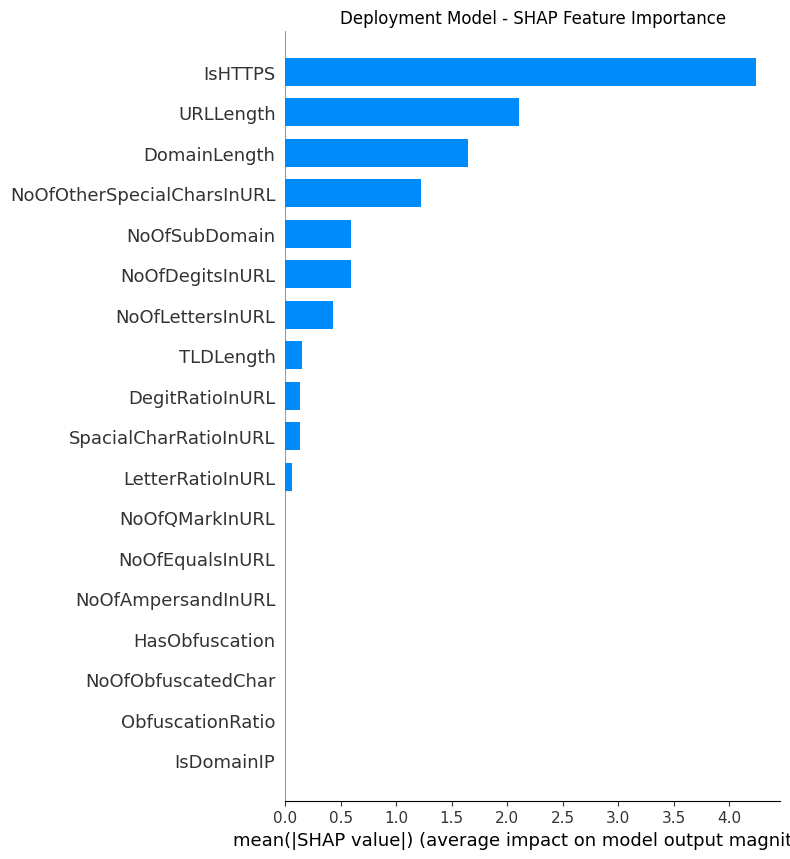

In [ ]:
#15.2
# Calculate mean absolute SHAP value
shap_importance = np.abs(
    deployment_shap_values
).mean(axis=0)

deployment_importance_df = pd.DataFrame({
    "Feature": X_shap_new.columns,
    "Mean_Absolute_SHAP": shap_importance
})

deployment_importance_df = deployment_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("TOP 10 IMPORTANT FEATURES")
display(deployment_importance_df.head(10))

# Save feature importance
deployment_importance_df.to_csv(
    os.path.join(
        explain_folder,
        "deployment_shap_importance.csv"
    ),
    index=False
)

# Plot global feature importance
plt.figure(figsize=(10, 7))

shap.summary_plot(
    deployment_shap_values,
    X_shap_new,
    plot_type="bar",
    show=False
)

plt.title("Deployment Model - SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(
        explain_folder,
        "deployment_shap_bar.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

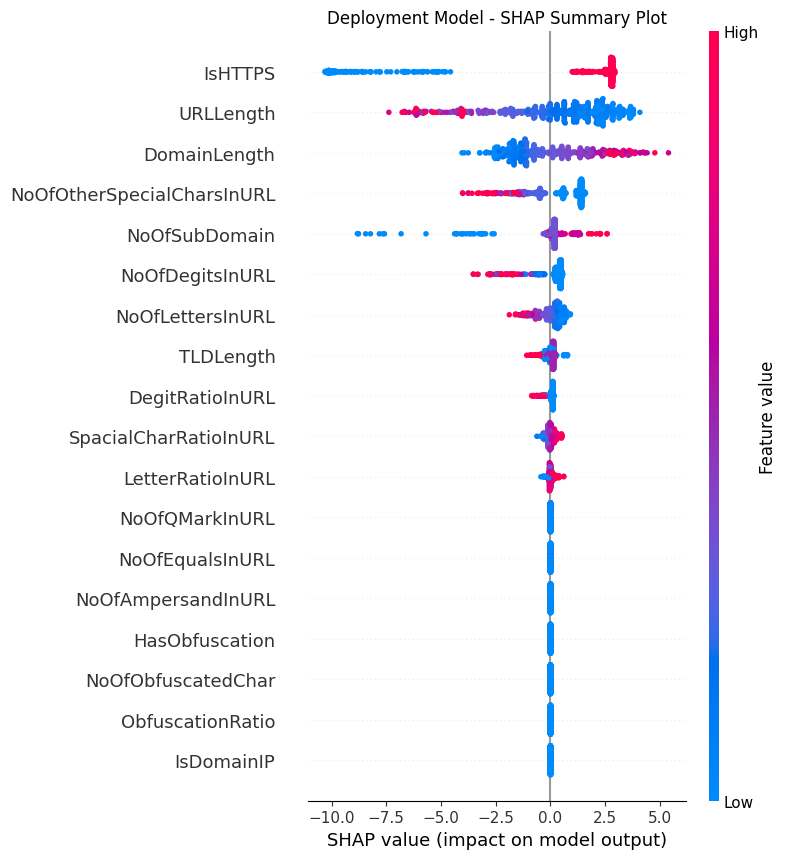

In [ ]:
#15.3
plt.figure(figsize=(10, 8))

shap.summary_plot(
    deployment_shap_values,
    X_shap_new,
    show=False
)

plt.title("Deployment Model - SHAP Summary Plot")
plt.tight_layout()

plt.savefig(
    os.path.join(
        explain_folder,
        "deployment_shap_summary.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#15.4
# Select one URL from the untouched test set
sample_index = X_test_new.index[0]

sample_url = df_clean.loc[sample_index, "URL"]
sample_features = X_test_new.loc[[sample_index]]

prediction = deployment_model.predict(sample_features)[0]
probabilities = deployment_model.predict_proba(sample_features)[0]

print("URL:", sample_url)
print("Actual label:", y_test_new.loc[sample_index])
print("Predicted label:", prediction)
print("Phishing probability:", round(probabilities[0] * 100, 2), "%")
print("Legitimate probability:", round(probabilities[1] * 100, 2), "%")

URL: https://www.uni-mainz.de
Actual label: 1
Predicted label: 1
Phishing probability: 5.13 %
Legitimate probability: 94.87 %


In [ ]:
import os

explainability_folder = "/content/drive/MyDrive/PhishGuard/explainability"

os.makedirs(explainability_folder, exist_ok=True)

print("Folder ready:", explainability_folder)

Folder ready: /content/drive/MyDrive/PhishGuard/explainability


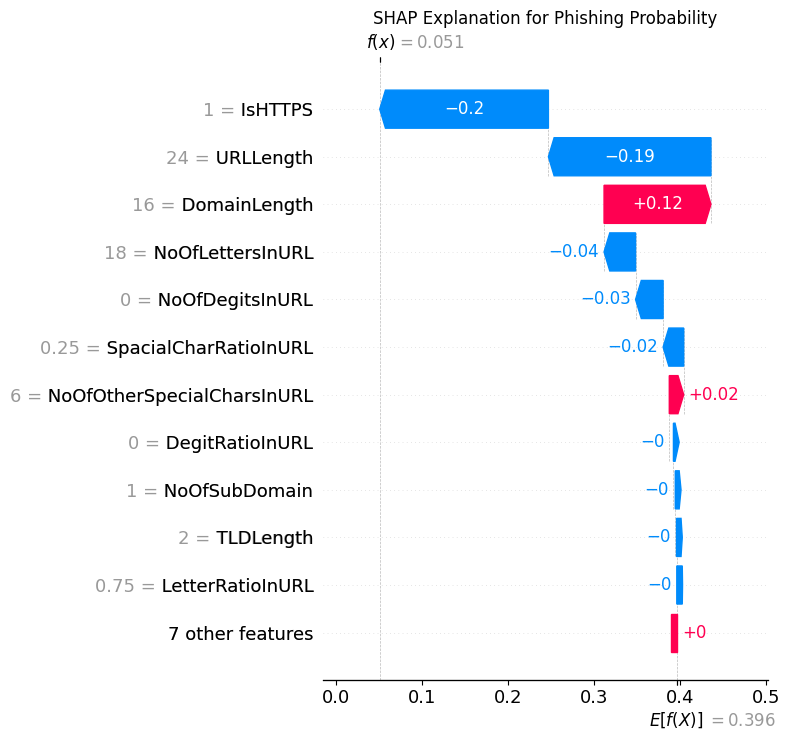

In [ ]:
#15.4.2
import shap
import matplotlib.pyplot as plt
import numpy as np

# Small background sample for SHAP
background = X_train_new.sample(
    n=min(100, len(X_train_new)),
    random_state=42
)

# Explain predicted probabilities
local_explainer = shap.TreeExplainer(
    deployment_model,
    data=background,
    model_output="probability"
)

local_explanation = local_explainer(sample_features)

# Select SHAP values for phishing (class 0)
values = local_explanation.values
base_values = local_explanation.base_values

if values.ndim == 3:
    phishing_values = values[0, :, 0]
    phishing_base = (
        base_values[0, 0]
        if np.ndim(base_values) > 1
        else base_values[0]
    )
else:
    # Binary single-output explanations represent class 1.
    # Invert them to explain class 0 probability.
    phishing_values = -values[0]
    phishing_base = 1 - np.asarray(base_values).reshape(-1)[0]

# Create a SHAP explanation for the waterfall plot
phishing_explanation = shap.Explanation(
    values=phishing_values,
    base_values=phishing_base,
    data=sample_features.iloc[0].values,
    feature_names=url_features
)

plt.figure(figsize=(10, 7))
shap.plots.waterfall(
    phishing_explanation,
    max_display=12,
    show=False
)

plt.title("SHAP Explanation for Phishing Probability")
plt.tight_layout()

plt.savefig(
    os.path.join(
        explainability_folder,
        "individual_url_shap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#15.5.1
import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Features that should remain unchanged
binary_features = [
    "IsDomainIP",
    "HasObfuscation",
    "IsHTTPS"
]

# Features that represent integer counts or lengths
integer_features = [
    "URLLength",
    "DomainLength",
    "TLDLength",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL"
]

# Calculate feature ranges using training data only
feature_min = X_train_new.min()
feature_max = X_train_new.max()
feature_range = feature_max - feature_min

# Evaluate the original, unmodified test data
results = []

def evaluate_robustness(X, level):
    predictions = deployment_model.predict(X)
    probabilities = deployment_model.predict_proba(X)

    phishing_probability = probabilities[:, 0]

    return {
        "Perturbation": level,
        "Accuracy": accuracy_score(y_test_new, predictions),
        "Phishing_Precision": precision_score(
            y_test_new, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing_Recall": recall_score(
            y_test_new, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing_F1": f1_score(
            y_test_new, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing_ROC_AUC": roc_auc_score(
            (y_test_new == 0).astype(int),
            phishing_probability
        )
    }

# Baseline
results.append(
    evaluate_robustness(X_test_new, "Original")
)

# Perturbation experiments
rng = np.random.default_rng(42)

for level in [0.05, 0.10, 0.20]:

    X_perturbed = X_test_new.copy()

    for feature in url_features:

        # Keep binary features unchanged
        if feature in binary_features:
            continue

        noise = rng.uniform(
            -level,
            level,
            size=len(X_perturbed)
        )

        X_perturbed[feature] = (
            X_perturbed[feature]
            + noise * feature_range[feature]
        )

        # Keep values within training-data limits
        X_perturbed[feature] = X_perturbed[feature].clip(
            lower=feature_min[feature],
            upper=feature_max[feature]
        )

        # Round count and length features
        if feature in integer_features:
            X_perturbed[feature] = (
                X_perturbed[feature].round()
            )

    # Keep ratios within their valid range
    ratio_features = [
        "ObfuscationRatio",
        "LetterRatioInURL",
        "DegitRatioInURL",
        "SpacialCharRatioInURL"
    ]

    for feature in ratio_features:
        X_perturbed[feature] = X_perturbed[feature].clip(0, 1)

    results.append(
        evaluate_robustness(
            X_perturbed,
            f"{int(level * 100)}%"
        )
    )

# Display results
robustness_df = pd.DataFrame(results)

print("DEPLOYMENT MODEL - ROBUSTNESS RESULTS")
print("=" * 60)

display(
    robustness_df.round(4)
)

DEPLOYMENT MODEL - ROBUSTNESS RESULTS


,Perturbation,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Phishing_ROC_AUC
0,Original,0.9948,0.9939,0.9916,0.9927,0.9977
1,5%,0.5612,0.4475,0.9251,0.6032,0.7696
2,10%,0.5021,0.4140,0.9166,0.5703,0.7194
3,20%,0.4887,0.4071,0.9153,0.5635,0.7044


In [ ]:
#15.5.2
robustness_path = os.path.join(
    explainability_folder,
    "deployment_robustness_results.csv"
)

robustness_df.to_csv(
    robustness_path,
    index=False
)

print("Robustness results saved!")
print(robustness_path)

Robustness results saved!
/content/drive/MyDrive/PhishGuard/explainability/deployment_robustness_results.csv


In [ ]:
import os

project_folder = "/content/drive/MyDrive/PhishGuard"

folders = [
    "artifacts",
    "explainability",
    "app"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_folder, folder),
        exist_ok=True
    )

print("PhishGuard project structure created!")

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}    {file}")

PhishGuard project structure created!
PhishGuard/
    deployment_model.joblib
    url_features.json
    test_metrics.json
    explainability/
        deployment_shap_importance.csv
        deployment_shap_bar.png
        deployment_shap_summary.png
        individual_url_shap.png
        deployment_robustness_results.csv
        deployment_robustness.png
        top_phishing_domains.csv
        top_phishing_rates.csv
        tld_phishing_analysis.csv
        model_comparison.csv
        webpage_feature_importance.csv
        ablation_comparison.csv
        feature_label_correlations.csv
        ablation_feature_importance.csv
        strict_unseen_vector_results.csv
        artifacts/
            deployment_model.joblib
            url_features.json
            test_metrics.json
            webpage_model.joblib
            webpage_model_features.json
    app/
        feature_extractor.py
        app.py
        requirements.txt
        __pycache__/
            feature_extractor.cpython-

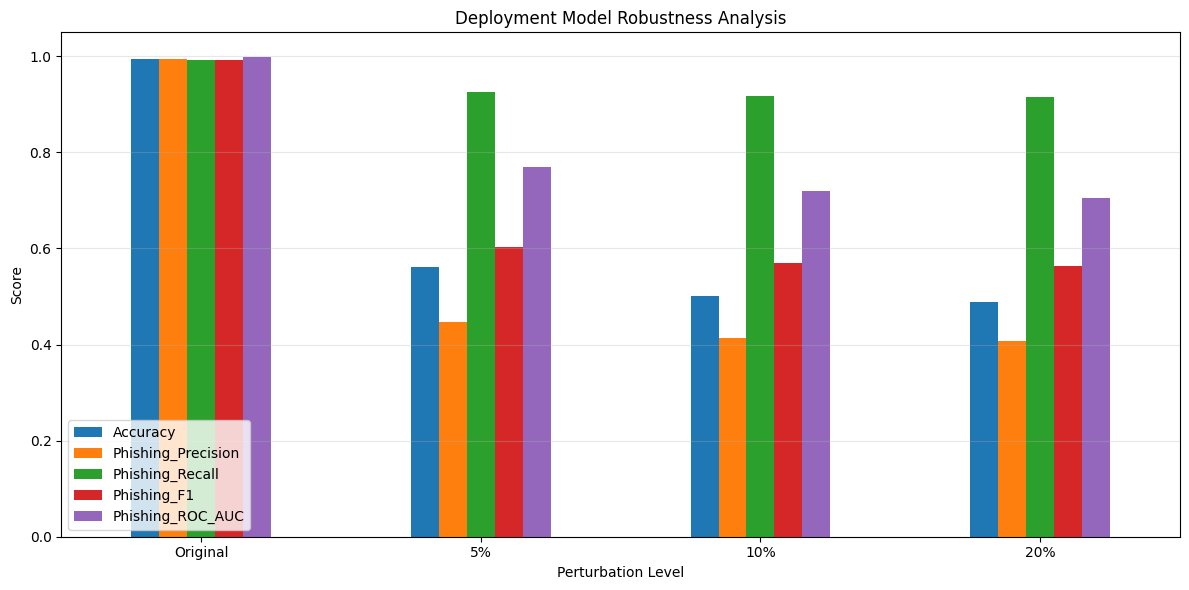

In [ ]:
#15.5.3
import matplotlib.pyplot as plt

metrics_to_plot = [
    "Accuracy",
    "Phishing_Precision",
    "Phishing_Recall",
    "Phishing_F1",
    "Phishing_ROC_AUC"
]

plot_df = robustness_df.set_index("Perturbation")

ax = plot_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Deployment Model Robustness Analysis")
plt.xlabel("Perturbation Level")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        explainability_folder,
        "deployment_robustness.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%%writefile /content/drive/MyDrive/PhishGuard/app/feature_extractor.py

import re
import ipaddress
from urllib.parse import urlsplit

def extract_url_features(url):

    url = str(url).strip()

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "http://" + url

    parsed = urlsplit(url)
    hostname = parsed.hostname or ""

    try:
        ipaddress.ip_address(hostname)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    labels = hostname.lower().split(".")
    tld = labels[-1] if len(labels) > 1 else ""

    no_of_subdomain = max(0, len(labels) - 2)

    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    encoded_chars = re.findall(
        r"%[0-9a-fA-F]{2}", url
    )

    equals_count = url.count("=")
    question_count = url.count("?")
    ampersand_count = url.count("&")

    other_special = sum(
        not c.isalnum() and c not in "=?&"
        for c in url
    )

    letter_ratio = letters / len(url) if url else 0
    digit_ratio = digits / len(url) if url else 0
    special_ratio = other_special / len(url) if url else 0
    obfuscation_ratio = len(encoded_chars) / len(url) if url else 0

    return {
        "URLLength": len(url),
        "DomainLength": len(hostname),
        "IsDomainIP": is_domain_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": int(len(encoded_chars) > 0),
        "NoOfObfuscatedChar": len(encoded_chars),
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": equals_count,
        "NoOfQMarkInURL": question_count,
        "NoOfAmpersandInURL": ampersand_count,
        "NoOfOtherSpecialCharsInURL": other_special,
        "SpacialCharRatioInURL": special_ratio,
        "IsHTTPS": int(parsed.scheme.lower() == "https")
    }

Overwriting /content/drive/MyDrive/PhishGuard/app/feature_extractor.py


In [ ]:
#16.3
import shutil
import os

artifacts_folder = os.path.join(
    project_folder, "artifacts"
)

files_to_copy = [
    "deployment_model.joblib",
    "url_features.json",
    "test_metrics.json"
]

for filename in files_to_copy:

    source = os.path.join(
        project_folder, filename
    )

    destination = os.path.join(
        artifacts_folder, filename
    )

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("MISSING:", filename)

print("\nArtifacts folder:")
print(os.listdir(artifacts_folder))

Copied: deployment_model.joblib
Copied: url_features.json
Copied: test_metrics.json

Artifacts folder:
['deployment_model.joblib', 'url_features.json', 'test_metrics.json']


In [ ]:
#16.4
import sys
import json
import joblib
import pandas as pd

app_folder = os.path.join(project_folder, "app")

sys.path.insert(0, app_folder)

from feature_extractor import extract_url_features

# Load saved model
saved_model = joblib.load(
    os.path.join(artifacts_folder, "deployment_model.joblib")
)

# Load feature names
with open(
    os.path.join(artifacts_folder, "url_features.json"),
    "r"
) as f:
    saved_features = json.load(f)

# Test URL
test_url = "https://www.google.com"

# Extract features
features = extract_url_features(test_url)

# Convert to model input
input_df = pd.DataFrame(
    [features],
    columns=saved_features
)

# Predict
prediction = saved_model.predict(input_df)[0]
probabilities = saved_model.predict_proba(input_df)[0]

print("URL:", test_url)
print("Extracted features:", len(features))
print("Prediction:", "Phishing" if prediction == 0 else "Legitimate")
print("Phishing probability:", round(probabilities[0] * 100, 2), "%")
print("Legitimate probability:", round(probabilities[1] * 100, 2), "%")

URL: https://www.google.com
Extracted features: 18
Prediction: Legitimate
Phishing probability: 0.36 %
Legitimate probability: 99.64 %


In [ ]:
%%writefile /content/drive/MyDrive/PhishGuard/app/app.py
#17.1
import os
import json
import sys
import re
import ipaddress
import joblib
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from urllib.parse import urlsplit

# --------------------------------------------------
# PATHS AND CONFIGURATION
# --------------------------------------------------

APP_DIR = os.path.dirname(os.path.abspath(__file__))
PROJECT_DIR = os.path.dirname(APP_DIR)
ARTIFACTS_DIR = os.path.join(PROJECT_DIR, "artifacts")
EXPLAIN_DIR = os.path.join(PROJECT_DIR, "explainability")

sys.path.insert(0, APP_DIR)

from feature_extractor import extract_url_features

st.set_page_config(
    page_title="PhishGuard | URL Security",
    page_icon="🛡️",
    layout="wide"
)

# --------------------------------------------------
# LOAD MODEL AND ARTIFACTS
# --------------------------------------------------

@st.cache_resource
def load_model():
    model = joblib.load(
        os.path.join(ARTIFACTS_DIR, "deployment_model.joblib")
    )

    with open(
        os.path.join(ARTIFACTS_DIR, "url_features.json"),
        "r"
    ) as f:
        features = json.load(f)

    with open(
        os.path.join(ARTIFACTS_DIR, "test_metrics.json"),
        "r"
    ) as f:
        metrics = json.load(f)

    return model, features, metrics


model, feature_names, metrics = load_model()

# --------------------------------------------------
# URL VALIDATION
# --------------------------------------------------

def validate_url(url):

    url = url.strip()

    if not url:
        return False, "Please enter a URL."

    if any(ord(char) < 32 for char in url):
        return False, "The URL contains invalid control characters."

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "http://" + url

    try:
        parsed = urlsplit(url)
        hostname = parsed.hostname

        if not hostname:
            return False, "Please enter a valid URL with a domain."

        if " " in hostname:
            return False, "The domain cannot contain spaces."

        return True, url

    except ValueError:
        return False, "The URL format is invalid."


# --------------------------------------------------
# PREDICTION
# --------------------------------------------------

def predict_url(url):

    features = extract_url_features(url)

    input_df = pd.DataFrame(
        [[features[name] for name in feature_names]],
        columns=feature_names
    )

    prediction = int(model.predict(input_df)[0])
    probabilities = model.predict_proba(input_df)[0]

    return prediction, probabilities, input_df


# --------------------------------------------------
# SHAP EXPLANATION
# --------------------------------------------------

def show_shap_explanation(input_df):

    st.subheader("Why did the model make this prediction?")

    try:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(input_df)

        base_values = explainer.expected_value

        # Handle binary XGBoost SHAP output
        if isinstance(shap_values, list):
            values = np.asarray(shap_values[0])[0]
            base = np.asarray(base_values).reshape(-1)[0]

        else:
            values = np.asarray(shap_values)

            if values.ndim == 3:
                values = values[0, :, 0]
                base_array = np.asarray(base_values)
                base = (
                    base_array.reshape(-1)[0]
                )
            else:
                values = values[0]
                base = np.asarray(base_values).reshape(-1)[0]

                # Single-output binary explanation is for class 1.
                # Reverse its direction to explain phishing class 0.
                values = -values
                base = -base

        explanation = shap.Explanation(
            values=values,
            base_values=base,
            data=input_df.iloc[0].values,
            feature_names=feature_names
        )

        fig, ax = plt.subplots(figsize=(10, 6))
        shap.plots.waterfall(
            explanation,
            max_display=10,
            show=False
        )

        st.pyplot(plt.gcf())
        plt.close()

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "SHAP contribution": values
        })

        importance_df["Absolute contribution"] = (
            importance_df["SHAP contribution"].abs()
        )

        importance_df = importance_df.sort_values(
            "Absolute contribution",
            ascending=False
        )

        st.write("Most influential URL features:")
        st.dataframe(
            importance_df.head(10),
            use_container_width=True,
            hide_index=True
        )

    except Exception as error:
        st.warning(
            "The prediction worked, but the SHAP explanation "
            "could not be generated."
        )
        st.caption(str(error))


# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("🛡️ PhishGuard")

page = st.sidebar.radio(
    "Navigation",
    [
        "Home",
        "URL Scanner",
        "Model Performance",
        "Robustness Analysis",
        "About"
    ]
)

st.sidebar.divider()
st.sidebar.caption(
    "Explainable and Robust Machine Learning "
    "Framework for Phishing URL Detection"
)

# --------------------------------------------------
# HOME PAGE
# --------------------------------------------------

if page == "Home":

    st.title("🛡️ PhishGuard")
    st.subheader("Intelligent Phishing URL Detection")

    st.write(
        "PhishGuard uses machine learning to analyse URL "
        "characteristics and identify potentially phishing URLs."
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Test Accuracy",
        f"{metrics['accuracy'] * 100:.2f}%"
    )

    col2.metric(
        "Phishing ROC-AUC",
        f"{metrics['phishing_roc_auc']:.4f}"
    )

    col3.metric(
        "Input Features",
        len(feature_names)
    )

    st.divider()

    st.markdown("### What can PhishGuard do?")

    st.markdown("""
    - **URL scanning:** Analyse a URL without opening the website.
    - **Machine learning:** Classify URLs as phishing or legitimate.
    - **Explainable AI:** Understand which URL features influenced a prediction.
    - **Robustness analysis:** Examine model behaviour under synthetic feature perturbations.
    """)

    st.info(
        "Select URL Scanner from the sidebar to analyse a URL."
    )


# --------------------------------------------------
# URL SCANNER
# --------------------------------------------------

elif page == "URL Scanner":

    st.title("🔍 URL Security Scanner")

    st.write(
        "Enter a URL below. PhishGuard analyses its URL "
        "characteristics without visiting the website."
    )

    url_input = st.text_input(
        "Enter URL",
        placeholder="https://example.com"
    )

    if st.button("Analyse URL", type="primary"):

        valid, result = validate_url(url_input)

        if not valid:
            st.error(result)

        else:

            with st.spinner("Analysing URL..."):

                prediction, probabilities, input_df = (
                    predict_url(result)
                )

            phishing_probability = float(probabilities[0])
            legitimate_probability = float(probabilities[1])

            st.divider()

            if prediction == 0:

                st.error("⚠️ Potential Phishing URL")

            else:

                st.success("✅ Classified as Legitimate")

            col1, col2 = st.columns(2)

            col1.metric(
                "Phishing Probability",
                f"{phishing_probability * 100:.2f}%"
            )

            col2.metric(
                "Legitimate Probability",
                f"{legitimate_probability * 100:.2f}%"
            )

            st.progress(phishing_probability)

            with st.expander("View extracted URL features"):

                st.dataframe(
                    input_df.T.rename(
                        columns={0: "Extracted Value"}
                    ),
                    use_container_width=True
                )

            st.divider()

            show_shap_explanation(input_df)

            st.caption(
                "This is a machine-learning prediction, not a "
                "guarantee of website safety. Always verify "
                "suspicious links independently."
            )


# --------------------------------------------------
# MODEL PERFORMANCE
# --------------------------------------------------

elif page == "Model Performance":

    st.title("📊 Model Performance")

    st.write(
        "Evaluation of the deployment XGBoost model "
        "on the untouched test dataset."
    )

    col1, col2 = st.columns(2)

    col1.metric(
        "Accuracy",
        f"{metrics['accuracy'] * 100:.2f}%"
    )

    col2.metric(
        "Phishing ROC-AUC",
        f"{metrics['phishing_roc_auc']:.4f}"
    )

    st.subheader("Confusion Matrix")

    cm = np.array(metrics["confusion_matrix"])

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Phishing", "Actual Legitimate"],
        columns=["Predicted Phishing", "Predicted Legitimate"]
    )

    st.dataframe(cm_df, use_container_width=True)

    st.subheader("Classification Report")

    report = metrics["classification_report"]

    report_df = pd.DataFrame({
        "Class": ["Phishing", "Legitimate"],
        "Precision": [
            report["Phishing"]["precision"],
            report["Legitimate"]["precision"]
        ],
        "Recall": [
            report["Phishing"]["recall"],
            report["Legitimate"]["recall"]
        ],
        "F1-score": [
            report["Phishing"]["f1-score"],
            report["Legitimate"]["f1-score"]
        ]
    })

    st.dataframe(
        report_df.round(4),
        use_container_width=True,
        hide_index=True
    )


# --------------------------------------------------
# ROBUSTNESS ANALYSIS
# --------------------------------------------------

elif page == "Robustness Analysis":

    st.title("🧪 Robustness Analysis")

    robustness_path = os.path.join(
        EXPLAIN_DIR,
        "deployment_robustness_results.csv"
    )

    if os.path.exists(robustness_path):

        robustness_df = pd.read_csv(robustness_path)

        st.write(
            "Performance under controlled synthetic "
            "feature perturbations."
        )

        st.dataframe(
            robustness_df.round(4),
            use_container_width=True,
            hide_index=True
        )

        chart_df = robustness_df.set_index("Perturbation")

        st.line_chart(
            chart_df[
                [
                    "Accuracy",
                    "Phishing_Precision",
                    "Phishing_Recall",
                    "Phishing_F1",
                    "Phishing_ROC_AUC"
                ]
            ]
        )

        st.warning(
            "Synthetic feature perturbations may create "
            "combinations that do not correspond to real URLs. "
            "These results should not be interpreted as a "
            "complete test of real-world attack resistance."
        )

    else:

        st.info(
            "Robustness results have not been saved yet."
        )


# --------------------------------------------------
# ABOUT PAGE
# --------------------------------------------------

elif page == "About":

    st.title("About PhishGuard")

    st.subheader("Project Objective")

    st.write(
        "To develop an explainable and robust machine-learning "
        "framework for phishing URL detection."
    )

    st.subheader("Technology Stack")

    st.markdown("""
    - Python
    - XGBoost
    - Scikit-learn
    - SHAP
    - Pandas and NumPy
    - Matplotlib
    - Streamlit
    """)

    st.subheader("Dataset")

    st.write(
        "PhiUSIIL Phishing URL Dataset — UCI Machine Learning Repository."
    )

    st.subheader("Important Limitation")

    st.write(
        "PhishGuard analyses URL-derived features only. "
        "It does not inspect webpage content, execute scripts, "
        "or guarantee that a website is safe."
    )

Overwriting /content/drive/MyDrive/PhishGuard/app/app.py


In [ ]:
#17.2
%%writefile /content/drive/MyDrive/PhishGuard/app/requirements.txt

streamlit
pandas
numpy
scikit-learn
xgboost
shap
matplotlib
joblib

Overwriting /content/drive/MyDrive/PhishGuard/app/requirements.txt


In [ ]:
#17.3
app_folder = "/content/drive/MyDrive/PhishGuard/app"

print("APPLICATION FILES")
print("=" * 35)

for file in os.listdir(app_folder):
    print(file)

APPLICATION FILES
feature_extractor.py
__pycache__
app.py
requirements.txt


In [ ]:
#17
!pip -q install streamlit

In [ ]:
!streamlit --version

Streamlit, version 1.67.0


In [ ]:
!pip -q install pyngrok

In [ ]:
import subprocess
import time
import os

app_folder = "/content/drive/MyDrive/PhishGuard/app"

# Start Streamlit in the background
process = subprocess.Popen(
    [
        "streamlit",
        "run",
        os.path.join(app_folder, "app.py"),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(5)

print("Streamlit process started!")
print("Process ID:", process.pid)

Streamlit process started!
Process ID: 116714


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

project_folder = "/content/drive/MyDrive/PhishGuard"
app_folder = project_folder + "/app"
artifacts_folder = project_folder + "/artifacts"
explainability_folder = project_folder + "/explainability"

print("PHISHGUARD PROJECT FILES")
print("=" * 45)

for folder in [project_folder, app_folder,
               artifacts_folder, explainability_folder]:

    print("\nFolder:", folder)

    if os.path.exists(folder):
        for filename in os.listdir(folder):
            print("  ", filename)
    else:
        print("  Folder not found")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PHISHGUARD PROJECT FILES

Folder: /content/drive/MyDrive/PhishGuard
   deployment_model.joblib
   url_features.json
   test_metrics.json
   explainability
   app
   artifacts

Folder: /content/drive/MyDrive/PhishGuard/app
   feature_extractor.py
   __pycache__
   app.py
   requirements.txt

Folder: /content/drive/MyDrive/PhishGuard/artifacts
   deployment_model.joblib
   url_features.json
   test_metrics.json

Folder: /content/drive/MyDrive/PhishGuard/explainability
   deployment_shap_importance.csv
   deployment_shap_bar.png
   deployment_shap_summary.png
   individual_url_shap.png
   deployment_robustness_results.csv
   deployment_robustness.png
   artifacts
   top_phishing_domains.csv
   top_phishing_rates.csv
   tld_phishing_analysis.csv
   model_comparison.csv
   webpage_feature_importance.csv
   ablation_comparison.csv
   feature_label_correlations.csv


In [ ]:
print("Checking restored variables...")

required_variables = [
    "df_clean",
    "raw_features_df",
    "y_raw",
    "X_train_new",
    "X_val_new",
    "X_test_new",
    "y_train_new",
    "y_val_new",
    "y_test_new",
    "domain_groups",
    "deployment_model"
]

for variable in required_variables:
    print(variable, ":", variable in globals())

Checking restored variables...
df_clean : True
raw_features_df : True
y_raw : True
X_train_new : True
X_val_new : True
X_test_new : True
y_train_new : True
y_val_new : True
y_test_new : True
domain_groups : True
deployment_model : True


In [ ]:

import os

project_folder = "/content/drive/MyDrive/PhishGuard"
app_folder = project_folder + "/app"
artifacts_folder = project_folder + "/artifacts"
explainability_folder = project_folder + "/explainability"

print("PHISHGUARD PROJECT")
print("=" * 50)

for folder in [project_folder, artifacts_folder,
               explainability_folder, app_folder]:

    print("\n", folder)

    if os.path.exists(folder):
        for filename in sorted(os.listdir(folder)):
            print("  ", filename)
    else:
        print("  FOLDER NOT FOUND")


PHISHGUARD PROJECT

 /content/drive/MyDrive/PhishGuard
   app
   artifacts
   deployment_model.joblib
   explainability
   test_metrics.json
   url_features.json

 /content/drive/MyDrive/PhishGuard/artifacts
   deployment_model.joblib
   test_metrics.json
   url_features.json

 /content/drive/MyDrive/PhishGuard/explainability
   ablation_comparison.csv
   ablation_feature_importance.csv
   artifacts
   deployment_robustness.png
   deployment_robustness_results.csv
   deployment_shap_bar.png
   deployment_shap_importance.csv
   deployment_shap_summary.png
   feature_label_correlations.csv
   individual_url_shap.png
   model_comparison.csv
   strict_unseen_vector_results.csv
   tld_phishing_analysis.csv
   top_phishing_domains.csv
   top_phishing_rates.csv
   webpage_feature_importance.csv

 /content/drive/MyDrive/PhishGuard/app
   __pycache__
   app.py
   feature_extractor.py
   requirements.txt


In [ ]:

required_variables = [
    "df_clean",
    "raw_features_df",
    "y_raw",
    "domain_groups",
    "X_train_new",
    "X_val_new",
    "X_test_new",
    "y_train_new",
    "y_val_new",
    "y_test_new",
    "deployment_model"
]

print("VARIABLE RESTORATION CHECK")
print("=" * 45)

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Not available'}")


VARIABLE RESTORATION CHECK
df_clean: Available
raw_features_df: Available
y_raw: Available
domain_groups: Available
X_train_new: Available
X_val_new: Available
X_test_new: Available
y_train_new: Available
y_val_new: Available
y_test_new: Available
deployment_model: Available


In [ ]:

import os

print("CSV FILES IN GOOGLE DRIVE")
print("=" * 45)

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in
               ["__pycache__", ".ipynb_checkpoints"]]

    for filename in files:
        if filename.lower().endswith(".csv"):
            print(os.path.join(root, filename))


CSV FILES IN GOOGLE DRIVE
/content/drive/MyDrive/TGFBR1_Kidney_Fibrosis_IC50.csv
/content/drive/MyDrive/PhishGuard/explainability/deployment_shap_importance.csv
/content/drive/MyDrive/PhishGuard/explainability/deployment_robustness_results.csv
/content/drive/MyDrive/PhishGuard/explainability/top_phishing_domains.csv
/content/drive/MyDrive/PhishGuard/explainability/top_phishing_rates.csv
/content/drive/MyDrive/PhishGuard/explainability/tld_phishing_analysis.csv
/content/drive/MyDrive/PhishGuard/explainability/model_comparison.csv
/content/drive/MyDrive/PhishGuard/explainability/webpage_feature_importance.csv
/content/drive/MyDrive/PhishGuard/explainability/ablation_comparison.csv
/content/drive/MyDrive/PhishGuard/explainability/feature_label_correlations.csv
/content/drive/MyDrive/PhishGuard/explainability/ablation_feature_importance.csv
/content/drive/MyDrive/PhishGuard/explainability/strict_unseen_vector_results.csv


In [ ]:
#18.4

import pandas as pd
import os

explainability_folder = "/content/drive/MyDrive/PhishGuard/explainability"

# Load previously generated results
top_by_count = pd.read_csv(
    explainability_folder + "/top_phishing_domains.csv"
)

top_by_rate = pd.read_csv(
    explainability_folder + "/top_phishing_rates.csv"
)

tld_summary = pd.read_csv(
    explainability_folder + "/tld_phishing_analysis.csv"
)

print("=" * 65)
print("TOP DOMAINS BY NUMBER OF PHISHING URLS")
print("=" * 65)
display(top_by_count.head(15))

print("\nTOP DOMAINS BY PHISHING RATE")
display(top_by_rate.head(15))

print("\nTLD PHISHING ANALYSIS")
display(tld_summary.head(15))


TOP DOMAINS BY NUMBER OF PHISHING URLS


,Domain,Total_URLs,Phishing_URLs,Legitimate_URLs,Phishing_Rate
0,web.app,5718,5718,0,100.000000
1,firebaseapp.com,5546,5546,0,100.000000
2,repl.co,3746,3746,0,100.000000
3,weeblysite.com,3079,3079,0,100.000000
4,ipfs.io,1552,1552,0,100.000000
5,workers.dev,1423,1423,0,100.000000
6,square.site,1187,1187,0,100.000000
7,dweb.link,959,959,0,100.000000
8,xsph.ru,928,928,0,100.000000
9,pantheonsite.io,891,891,0,100.000000



TOP DOMAINS BY PHISHING RATE


,Domain,Total_URLs,Phishing_URLs,Legitimate_URLs,Phishing_Rate
0,zzz.com.ua,47,47,0,100.0
1,00-coveriy-tm.quest,5,5,0,100.0
2,000space.com,9,9,0,100.0
3,000webhostapp.com,98,98,0,100.0
4,0fees.net,7,7,0,100.0
5,0hi.me,11,11,0,100.0
6,10096101534410096410.com,7,7,0,100.0
7,10web.site,8,8,0,100.0
8,117.6.207.182,5,5,0,100.0
9,129.226.210.78,30,30,0,100.0



TLD PHISHING ANALYSIS


,TLD,Total_URLs,Phishing_URLs,Legitimate_URLs,Phishing_Rate
0,com,112382,43597,68785,38.793579
1,app,6467,6327,140,97.835163
2,co,5408,4950,458,91.531065
3,io,4174,3742,432,89.650216
4,net,7076,3078,3998,43.499152
5,ru,3870,2978,892,76.950904
6,top,2327,2325,2,99.914052
7,dev,2322,2289,33,98.578811
8,org,18792,2268,16524,12.068966
9,site,1470,1465,5,99.659864


In [ ]:

# STEP 18.5 - WEBPAGE FEATURE INSPECTION

webpage_features = [
    "LineOfCode",
    "LargestLineLength",
    "HasTitle",
    "DomainTitleMatchScore",
    "URLTitleMatchScore",
    "HasFavicon",
    "Robots",
    "IsResponsive",
    "NoOfURLRedirect",
    "NoOfSelfRedirect",
    "HasDescription",
    "NoOfPopup",
    "NoOfiFrame",
    "HasExternalFormSubmit",
    "HasSocialNet",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasPasswordField",
    "Bank",
    "Pay",
    "Crypto",
    "HasCopyrightInfo",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

print("Number of webpage features:", len(webpage_features))

missing = [
    col for col in webpage_features
    if col not in df_clean.columns
]

print("Missing columns:", missing)

print("\nDATA TYPES")
display(df_clean[webpage_features].dtypes.to_frame("Data Type"))

print("\nMISSING VALUES")
display(
    df_clean[webpage_features]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nSAMPLE RECORDS")
display(df_clean[webpage_features].head())


Number of webpage features: 28
Missing columns: []

DATA TYPES


,Data Type
LineOfCode,int64
LargestLineLength,int64
HasTitle,int64
DomainTitleMatchScore,float64
URLTitleMatchScore,float64
HasFavicon,int64
Robots,int64
IsResponsive,int64
NoOfURLRedirect,int64
NoOfSelfRedirect,int64



MISSING VALUES


,Missing Values
LineOfCode,0
LargestLineLength,0
HasTitle,0
DomainTitleMatchScore,0
URLTitleMatchScore,0
HasFavicon,0
Robots,0
IsResponsive,0
NoOfURLRedirect,0
NoOfSelfRedirect,0



SAMPLE RECORDS


,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,558,9381,1,0.000000,0.000000,0,1,1,0,0,...,1,0,0,1,34,20,28,119,0,124
1,618,9381,1,55.555556,55.555556,1,1,0,0,0,...,0,0,0,1,50,9,8,39,0,217
2,467,682,1,46.666667,46.666667,0,1,1,0,0,...,0,0,0,1,10,2,7,42,2,5
3,6356,26824,1,0.000000,0.000000,0,1,1,0,0,...,0,1,1,1,3,27,15,22,1,31
4,6089,28404,1,100.000000,100.000000,0,1,1,1,1,...,1,1,0,1,244,15,34,72,1,85


In [ ]:
#19.1

# STEP 19.1 - COMBINE URL AND WEBPAGE FEATURES

import pandas as pd
import numpy as np

# Existing 18 URL features
url_features = list(raw_features_df.columns)

# 28 webpage features
webpage_features = [
    "LineOfCode",
    "LargestLineLength",
    "HasTitle",
    "DomainTitleMatchScore",
    "URLTitleMatchScore",
    "HasFavicon",
    "Robots",
    "IsResponsive",
    "NoOfURLRedirect",
    "NoOfSelfRedirect",
    "HasDescription",
    "NoOfPopup",
    "NoOfiFrame",
    "HasExternalFormSubmit",
    "HasSocialNet",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasPasswordField",
    "Bank",
    "Pay",
    "Crypto",
    "HasCopyrightInfo",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

# Extract webpage features using the same dataframe index
webpage_df = df_clean[webpage_features].copy()

# Combine both feature groups
X_combined = pd.concat(
    [raw_features_df, webpage_df],
    axis=1
)

# Ensure all columns are numeric
X_combined = X_combined.apply(pd.to_numeric)

# Check the combined dataset
print("COMBINED DATASET")
print("=" * 45)
print("Shape:", X_combined.shape)
print("URL features:", len(url_features))
print("Webpage features:", len(webpage_features))
print("Total features:", X_combined.shape[1])

print("\nMissing values:", X_combined.isnull().sum().sum())
print("Infinite values:", np.isinf(X_combined.to_numpy()).sum())
print("Duplicate feature names:", X_combined.columns.duplicated().sum())

assert X_combined.shape[1] == 46
assert X_combined.index.equals(y_raw.index)
assert X_combined.isnull().sum().sum() == 0
assert np.isfinite(X_combined.to_numpy()).all()

print("\nAll checks passed!")


COMBINED DATASET
Shape: (235370, 46)
URL features: 18
Webpage features: 28
Total features: 46

Missing values: 0
Infinite values: 0
Duplicate feature names: 0

All checks passed!


In [ ]:

# STEP 19.2 - USE THE EXISTING DOMAIN-SEPARATED SPLIT

X_train_combined = X_combined.iloc[train_positions].copy()
X_val_combined = X_combined.iloc[val_positions].copy()
X_test_combined = X_combined.iloc[test_positions].copy()

# Use the existing labels
y_train_combined = y_raw.iloc[train_positions].copy()
y_val_combined = y_raw.iloc[val_positions].copy()
y_test_combined = y_raw.iloc[test_positions].copy()

print("TRAINING:", X_train_combined.shape)
print("VALIDATION:", X_val_combined.shape)
print("TESTING:", X_test_combined.shape)

# Verify feature and label alignment
assert X_train_combined.index.equals(y_train_combined.index)
assert X_val_combined.index.equals(y_val_combined.index)
assert X_test_combined.index.equals(y_test_combined.index)

print("\nFeature-label alignment verified!")


TRAINING: (159383, 46)
VALIDATION: (44309, 46)
TESTING: (31678, 46)

Feature-label alignment verified!


In [ ]:

# STEP 19.3 - TRAIN WEBPAGE-ASSISTED MODEL

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Copy the existing model configuration
webpage_model = XGBClassifier(
    **deployment_model.get_params()
)

# Balance the training classes
webpage_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_combined
)

# Train using URL + webpage features
webpage_model.fit(
    X_train_combined,
    y_train_combined,
    sample_weight=webpage_weights,
    verbose=False
)

print("Webpage-assisted XGBoost model trained successfully!")
print("Number of input features:", webpage_model.n_features_in_)


Webpage-assisted XGBoost model trained successfully!
Number of input features: 46


In [ ]:

# STEP 19.4 - MODEL B EVALUATION

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Validation predictions
val_predictions = webpage_model.predict(X_val_combined)
val_probabilities = webpage_model.predict_proba(X_val_combined)[:, 0]

print("WEBPAGE MODEL - VALIDATION RESULTS")
print("=" * 55)

print("Accuracy:", round(
    accuracy_score(y_val_combined, val_predictions), 4
))

print("Phishing ROC-AUC:", round(
    roc_auc_score(
        (y_val_combined == 0).astype(int),
        val_probabilities
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val_combined,
    val_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))

# Final test evaluation
test_predictions = webpage_model.predict(X_test_combined)
test_probabilities = webpage_model.predict_proba(X_test_combined)[:, 0]

webpage_test_accuracy = accuracy_score(
    y_test_combined, test_predictions
)

webpage_test_auc = roc_auc_score(
    (y_test_combined == 0).astype(int),
    test_probabilities
)

webpage_cm = confusion_matrix(
    y_test_combined,
    test_predictions,
    labels=[0, 1]
)

print("\nWEBPAGE MODEL - FINAL TEST RESULTS")
print("=" * 55)

print("Accuracy:", round(webpage_test_accuracy, 4))
print("Phishing ROC-AUC:", round(webpage_test_auc, 4))

print("\nConfusion Matrix:")
print(webpage_cm)

print("\nClassification Report:")
print(classification_report(
    y_test_combined,
    test_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))


WEBPAGE MODEL - VALIDATION RESULTS
Accuracy: 0.9998
Phishing ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     23854
  Legitimate       1.00      1.00      1.00     20455

    accuracy                           1.00     44309
   macro avg       1.00      1.00      1.00     44309
weighted avg       1.00      1.00      1.00     44309


WEBPAGE MODEL - FINAL TEST RESULTS
Accuracy: 0.9999
Phishing ROC-AUC: 1.0

Confusion Matrix:
[[11421     1]
 [    1 20255]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     11422
  Legitimate       1.00      1.00      1.00     20256

    accuracy                           1.00     31678
   macro avg       1.00      1.00      1.00     31678
weighted avg       1.00      1.00      1.00     31678



In [ ]:

# STEP 19.5 - FAIR MODEL COMPARISON

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Model A: URL-only
model_a_predictions = deployment_model.predict(X_test_new)
model_a_probabilities = deployment_model.predict_proba(X_test_new)[:, 0]

# Model B: URL + webpage
model_b_predictions = webpage_model.predict(X_test_combined)
model_b_probabilities = webpage_model.predict_proba(X_test_combined)[:, 0]

# Convert labels: phishing = 1 for metric calculation
actual_phishing = (y_test_new == 0).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "URL-only",
        "Features": 18,
        "Accuracy": accuracy_score(
            y_test_new, model_a_predictions
        ),
        "Phishing_Precision": precision_score(
            actual_phishing,
            (model_a_predictions == 0).astype(int)
        ),
        "Phishing_Recall": recall_score(
            actual_phishing,
            (model_a_predictions == 0).astype(int)
        ),
        "Phishing_F1": f1_score(
            actual_phishing,
            (model_a_predictions == 0).astype(int)
        ),
        "Phishing_ROC_AUC": roc_auc_score(
            actual_phishing, model_a_probabilities
        )
    },
    {
        "Model": "URL + Webpage",
        "Features": 46,
        "Accuracy": accuracy_score(
            y_test_combined, model_b_predictions
        ),
        "Phishing_Precision": precision_score(
            actual_phishing,
            (model_b_predictions == 0).astype(int)
        ),
        "Phishing_Recall": recall_score(
            actual_phishing,
            (model_b_predictions == 0).astype(int)
        ),
        "Phishing_F1": f1_score(
            actual_phishing,
            (model_b_predictions == 0).astype(int)
        ),
        "Phishing_ROC_AUC": roc_auc_score(
            actual_phishing, model_b_probabilities
        )
    }
])

print("MODEL COMPARISON ON THE SAME TEST SET")
display(comparison.round(4))


MODEL COMPARISON ON THE SAME TEST SET


,Model,Features,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Phishing_ROC_AUC
0,URL-only,18,0.9948,0.9939,0.9916,0.9927,0.9977
1,URL + Webpage,46,0.9999,0.9999,0.9999,0.9999,1.0000


In [ ]:

# STEP 19.6 - SAVE WEBPAGE MODEL AND FEATURE LIST

import joblib
import json
import os

artifacts_folder = "/content/drive/MyDrive/PhishGuard/artifacts"

os.makedirs(artifacts_folder, exist_ok=True)

# Save trained model
joblib.dump(
    webpage_model,
    artifacts_folder + "/webpage_model.joblib"
)

# Save the complete 46-feature list
with open(
    artifacts_folder + "/webpage_model_features.json",
    "w"
) as f:
    json.dump(
        list(X_combined.columns),
        f,
        indent=4
    )

# Save model comparison
comparison.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/model_comparison.csv",
    index=False
)

print("Webpage model saved successfully!")
print("Saved files:")
print("- webpage_model.joblib")
print("- webpage_model_features.json")
print("- model_comparison.csv")


Webpage model saved successfully!
Saved files:
- webpage_model.joblib
- webpage_model_features.json
- model_comparison.csv


In [ ]:
import os

base_path = "/content/drive/MyDrive/PhishGuard"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file in [
            "webpage_model.joblib",
            "webpage_model_features.json",
            "model_comparison.csv"
        ]:
            print(os.path.join(root, file))

/content/drive/MyDrive/PhishGuard/explainability/model_comparison.csv
/content/drive/MyDrive/PhishGuard/explainability/artifacts/webpage_model.joblib
/content/drive/MyDrive/PhishGuard/explainability/artifacts/webpage_model_features.json
/content/drive/MyDrive/PhishGuard/artifacts/webpage_model.joblib
/content/drive/MyDrive/PhishGuard/artifacts/webpage_model_features.json


In [ ]:
import joblib
import json

model_path = "/content/drive/MyDrive/PhishGuard/artifacts/webpage_model.joblib"
features_path = "/content/drive/MyDrive/PhishGuard/artifacts/webpage_model_features.json"

webpage_model = joblib.load(model_path)

with open(features_path, "r") as f:
    webpage_model_features = json.load(f)

print("Webpage model loaded successfully!")
print("Number of features:", len(webpage_model_features))

Webpage model loaded successfully!
Number of features: 46


TOP 20 IMPORTANT FEATURES


,Feature,Importance
45,NoOfExternalRef,0.738691
43,NoOfSelfRef,0.075202
18,LineOfCode,0.060934
17,IsHTTPS,0.018898
32,HasSocialNet,0.017045
0,URLLength,0.012587
15,NoOfOtherSpecialCharsInURL,0.008765
40,NoOfImage,0.008669
39,HasCopyrightInfo,0.007857
28,HasDescription,0.005981


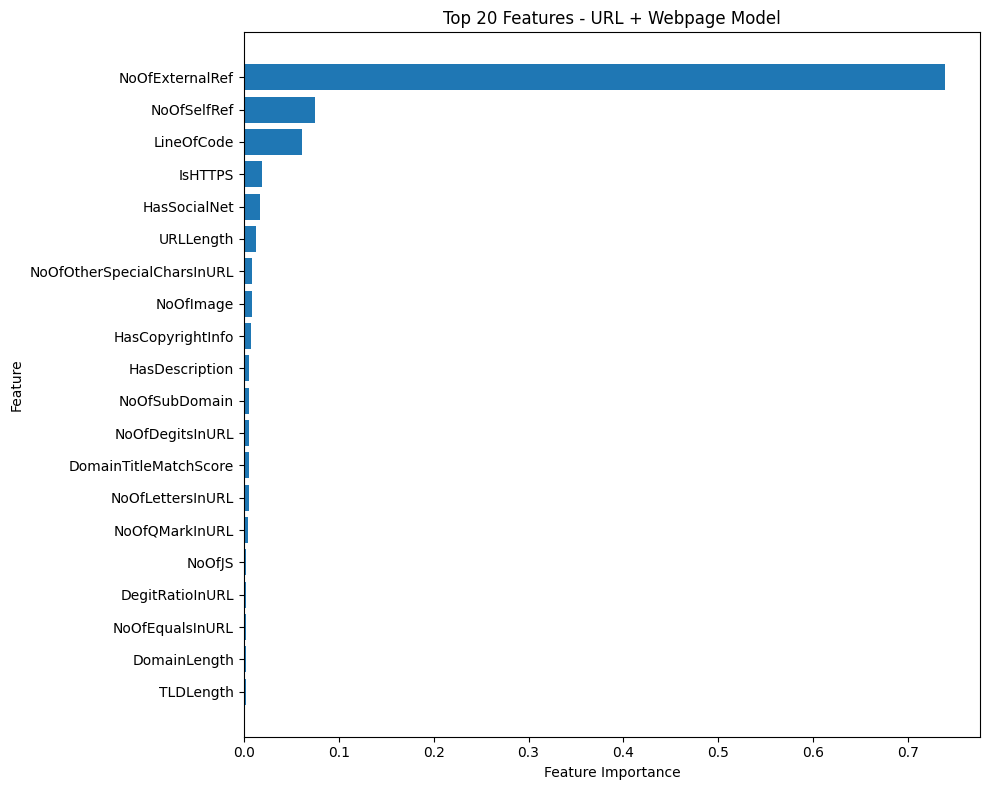

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": webpage_model.feature_names_in_,
    "Importance": webpage_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")
display(importance_df.head(20))

plt.figure(figsize=(10, 8))
top_features = importance_df.head(20).sort_values("Importance")

plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - URL + Webpage Model")
plt.tight_layout()
plt.show()

importance_df.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/webpage_feature_importance.csv",
    index=False
)

NoOfExternalRef - Class-wise statistics


,count,mean,median,std,min,max
Class,,,,,,
Legitimate,94139,84.345957,45.0,165.298274,0,16257
Phishing,65244,1.077095,0.0,3.311309,0,368



Percentile comparison


,0.00,0.25,0.50,0.75,0.90,0.95,0.99,1.00
Class,,,,,,,,
Legitimate,0.0,17.0,45.0,105.0,193.0,271.0,531.0,16257.0
Phishing,0.0,0.0,0.0,1.0,3.0,4.0,13.0,368.0


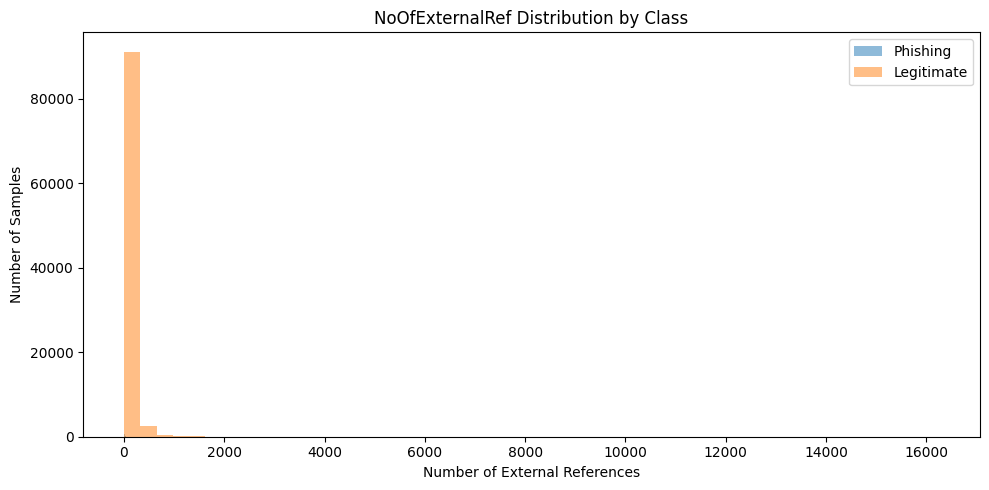

In [ ]:
#23
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Combine the training feature and label data
external_ref_analysis = pd.DataFrame({
    "NoOfExternalRef": X_train_combined["NoOfExternalRef"],
    "Label": y_train_combined
})

# Remember: 0 = Phishing, 1 = Legitimate
external_ref_analysis["Class"] = external_ref_analysis["Label"].map({
    0: "Phishing",
    1: "Legitimate"
})

# Summary statistics
summary = external_ref_analysis.groupby("Class")["NoOfExternalRef"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print("NoOfExternalRef - Class-wise statistics")
display(summary)

# Compare selected percentiles
percentiles = external_ref_analysis.groupby("Class")[
    "NoOfExternalRef"
].quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]).unstack()

print("\nPercentile comparison")
display(percentiles)

# Plot distributions
plt.figure(figsize=(10, 5))

for class_name in ["Phishing", "Legitimate"]:
    values = external_ref_analysis.loc[
        external_ref_analysis["Class"] == class_name,
        "NoOfExternalRef"
    ]
    plt.hist(values, bins=50, alpha=0.5, label=class_name)

plt.xlabel("Number of External References")
plt.ylabel("Number of Samples")
plt.title("NoOfExternalRef Distribution by Class")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

single_feature_train = X_train_combined[["NoOfExternalRef"]]
single_feature_test = X_test_combined[["NoOfExternalRef"]]

single_feature_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

single_feature_model.fit(
    single_feature_train,
    y_train_combined
)

single_predictions = single_feature_model.predict(single_feature_test)

print("SINGLE-FEATURE TEST RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test_combined, single_predictions), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_combined,
    single_predictions,
    labels=[0, 1]
))

print("\nClassification Report:")
print(classification_report(
    y_test_combined,
    single_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))

SINGLE-FEATURE TEST RESULTS
Accuracy: 0.9562

Confusion Matrix:
[[10977   445]
 [  943 19313]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       0.92      0.96      0.94     11422
  Legitimate       0.98      0.95      0.97     20256

    accuracy                           0.96     31678
   macro avg       0.95      0.96      0.95     31678
weighted avg       0.96      0.96      0.96     31678



In [ ]:
#ablation
#26.1
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Remove only NoOfExternalRef
X_train_ablation = X_train_combined.drop(
    columns=["NoOfExternalRef"]
)

X_val_ablation = X_val_combined.drop(
    columns=["NoOfExternalRef"]
)

X_test_ablation = X_test_combined.drop(
    columns=["NoOfExternalRef"]
)

print("Training shape:", X_train_ablation.shape)
print("Validation shape:", X_val_ablation.shape)
print("Testing shape:", X_test_ablation.shape)

assert X_train_ablation.shape[1] == 45
assert "NoOfExternalRef" not in X_train_ablation.columns

Training shape: (159383, 45)
Validation shape: (44309, 45)
Testing shape: (31678, 45)


In [ ]:
# Use the same XGBoost parameters as the original webpage model
ablation_model = XGBClassifier(
    **webpage_model.get_params()
)

# Balance the training samples
ablation_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_combined
)

# Train without NoOfExternalRef
ablation_model.fit(
    X_train_ablation,
    y_train_combined,
    sample_weight=ablation_weights,
    verbose=False
)

print("Ablation model trained successfully!")

Ablation model trained successfully!


In [ ]:
def evaluate_ablation(model, X, y, dataset_name):

    predictions = model.predict(X)

    # Class 0 = Phishing
    phishing_probabilities = model.predict_proba(X)[:, 0]

    print("\n" + "=" * 55)
    print(dataset_name)
    print("=" * 55)

    print("Accuracy:",
          round(accuracy_score(y, predictions), 4))

    print("Phishing Precision:",
          round(precision_score(y, predictions, pos_label=0), 4))

    print("Phishing Recall:",
          round(recall_score(y, predictions, pos_label=0), 4))

    print("Phishing F1:",
          round(f1_score(y, predictions, pos_label=0), 4))

    print("Phishing ROC-AUC:",
          round(roc_auc_score(
              (y == 0).astype(int),
              phishing_probabilities
          ), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y, predictions, labels=[0, 1]))

# Validation
evaluate_ablation(
    ablation_model,
    X_val_ablation,
    y_val_combined,
    "ABLATION MODEL - VALIDATION"
)

# Final test
evaluate_ablation(
    ablation_model,
    X_test_ablation,
    y_test_combined,
    "ABLATION MODEL - FINAL TEST"
)


ABLATION MODEL - VALIDATION
Accuracy: 0.9999
Phishing Precision: 1.0
Phishing Recall: 0.9998
Phishing F1: 0.9999
Phishing ROC-AUC: 1.0

Confusion Matrix:
[[23850     4]
 [    1 20454]]

ABLATION MODEL - FINAL TEST
Accuracy: 1.0
Phishing Precision: 1.0
Phishing Recall: 0.9999
Phishing F1: 1.0
Phishing ROC-AUC: 1.0

Confusion Matrix:
[[11421     1]
 [    0 20256]]


In [ ]:
# Evaluate predictions for all three models
models_to_compare = [
    ("URL-only", deployment_model, X_test_new),
    ("URL + Webpage", webpage_model, X_test_combined),
    ("URL + Webpage (without NoOfExternalRef)",
     ablation_model, X_test_ablation)
]

comparison_results = []

for name, model, X in models_to_compare:

    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 0]

    comparison_results.append({
        "Model": name,
        "Features": X.shape[1],
        "Accuracy": accuracy_score(y_test_combined, predictions),
        "Phishing_Precision": precision_score(
            y_test_combined, predictions, pos_label=0
        ),
        "Phishing_Recall": recall_score(
            y_test_combined, predictions, pos_label=0
        ),
        "Phishing_F1": f1_score(
            y_test_combined, predictions, pos_label=0
        ),
        "Phishing_ROC_AUC": roc_auc_score(
            (y_test_combined == 0).astype(int),
            probabilities
        )
    })

ablation_comparison = pd.DataFrame(comparison_results)

display(
    ablation_comparison.round(4)
)

ablation_comparison.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/ablation_comparison.csv",
    index=False
)

,Model,Features,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Phishing_ROC_AUC
0,URL-only,18,0.9948,0.9939,0.9916,0.9927,0.9977
1,URL + Webpage,46,0.9999,0.9999,0.9999,0.9999,1.0000
2,URL + Webpage (without NoOfExternalRef),45,1.0000,1.0000,0.9999,1.0000,1.0000


In [ ]:
import pandas as pd
import numpy as np

# Calculate correlation between every feature and the target
correlation_df = X_train_combined.copy()

correlation_df["Label"] = y_train_combined

correlations = (
    correlation_df.corr(numeric_only=True)["Label"]
    .drop("Label")
    .sort_values(key=abs, ascending=False)
)

print("FEATURES MOST CORRELATED WITH THE LABEL")
display(
    correlations.abs()
    .to_frame("Absolute_Correlation")
    .head(20)
)

print("\nSigned correlations:")
display(correlations.head(20))

# Save results
correlations.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/feature_label_correlations.csv"
)

FEATURES MOST CORRELATED WITH THE LABEL


,Absolute_Correlation
HasSocialNet,0.777790
HasCopyrightInfo,0.737078
HasDescription,0.678334
IsHTTPS,0.653507
IsResponsive,0.581214
HasSubmitButton,0.575357
DomainTitleMatchScore,0.568991
URLTitleMatchScore,0.527778
HasHiddenFields,0.487414
HasFavicon,0.477102



Signed correlations:


,Label
HasSocialNet,0.777790
HasCopyrightInfo,0.737078
HasDescription,0.678334
IsHTTPS,0.653507
IsResponsive,0.581214
HasSubmitButton,0.575357
DomainTitleMatchScore,0.568991
URLTitleMatchScore,0.527778
HasHiddenFields,0.487414
HasFavicon,0.477102


In [ ]:
# Check exact duplicate feature vectors across train and test

train_hashes = pd.util.hash_pandas_object(
    X_train_combined,
    index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test_combined,
    index=False
)

train_hash_set = set(train_hashes)

overlap_count = test_hashes.isin(train_hash_set).sum()

print("Train samples:", len(X_train_combined))
print("Test samples:", len(X_test_combined))
print("Identical feature rows across train and test:", overlap_count)
print(
    "Percentage of test rows duplicated in training:",
    round(overlap_count / len(X_test_combined) * 100, 4),
    "%"
)

Train samples: 159383
Test samples: 31678
Identical feature rows across train and test: 4363
Percentage of test rows duplicated in training: 13.773 %


TOP 20 FEATURES - ABLATION MODEL


,Feature,Importance
43,NoOfSelfRef,0.347873
18,LineOfCode,0.319167
32,HasSocialNet,0.148376
0,URLLength,0.026569
15,NoOfOtherSpecialCharsInURL,0.022066
17,IsHTTPS,0.016811
39,HasCopyrightInfo,0.016772
40,NoOfImage,0.015337
10,NoOfDegitsInURL,0.012047
28,HasDescription,0.011762


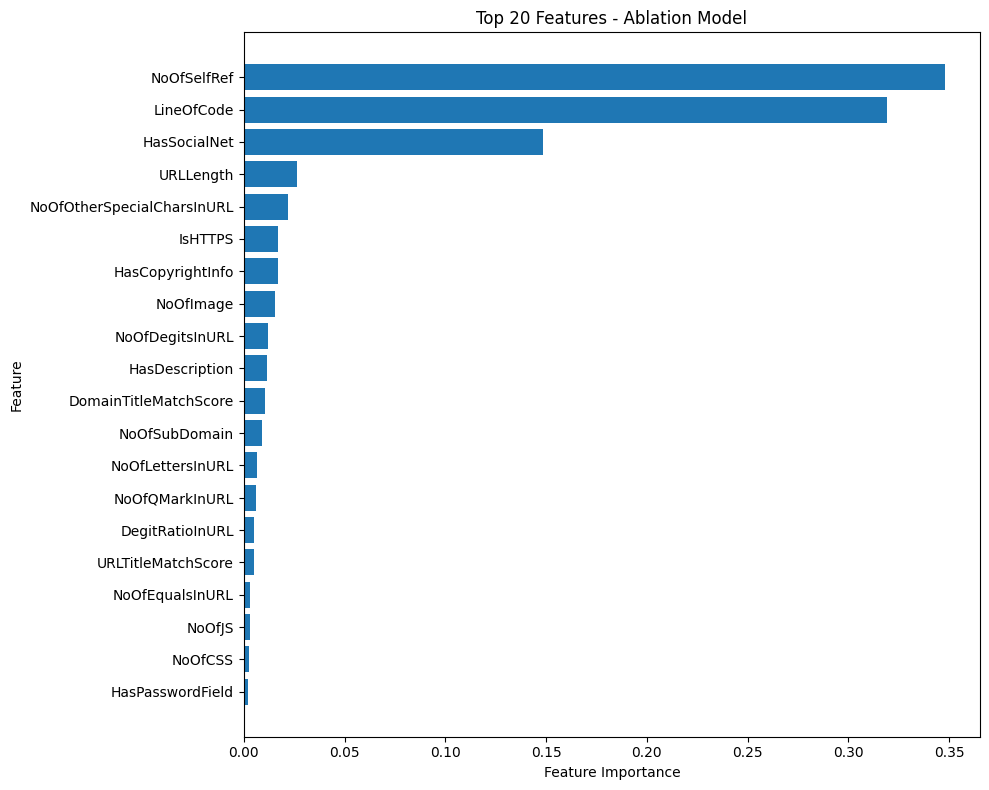

In [ ]:
ablation_importance = pd.DataFrame({
    "Feature": ablation_model.feature_names_in_,
    "Importance": ablation_model.feature_importances_
})

ablation_importance = ablation_importance.sort_values(
    "Importance",
    ascending=False
)

print("TOP 20 FEATURES - ABLATION MODEL")
display(ablation_importance.head(20))

plt.figure(figsize=(10, 8))

top_ablation = (
    ablation_importance.head(20)
    .sort_values("Importance")
)

plt.barh(
    top_ablation["Feature"],
    top_ablation["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - Ablation Model")
plt.tight_layout()
plt.show()

ablation_importance.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/ablation_feature_importance.csv",
    index=False
)

In [ ]:
# Combine feature vectors and labels
train_check = X_train_combined.copy()
train_check["Label"] = y_train_combined.values

test_check = X_test_combined.copy()
test_check["Label"] = y_test_combined.values

# Hash feature vectors without including labels
train_check["row_hash"] = pd.util.hash_pandas_object(
    X_train_combined,
    index=False
).values

test_check["row_hash"] = pd.util.hash_pandas_object(
    X_test_combined,
    index=False
).values

# Find feature vectors present in both sets
matched = test_check.merge(
    train_check[["row_hash", "Label"]],
    on="row_hash",
    how="inner",
    suffixes=("_test", "_train")
)

print("Matching feature vectors:", len(matched))

if len(matched) > 0:
    conflicts = matched[
        matched["Label_test"] != matched["Label_train"]
    ]

    print("Matching vectors with conflicting labels:", len(conflicts))
else:
    print("No matching feature vectors found.")

Matching feature vectors: 152808
Matching vectors with conflicting labels: 0


In [ ]:
#28
import pandas as pd
import numpy as np

feature_columns = list(X_train_combined.columns)

# Create copies with labels
train_audit = X_train_combined.copy()
train_audit["Label"] = y_train_combined.values

test_audit = X_test_combined.copy()
test_audit["Label"] = y_test_combined.values

# Generate hashes using FEATURES ONLY, not labels
train_audit["row_hash"] = pd.util.hash_pandas_object(
    X_train_combined,
    index=False
).values

test_audit["row_hash"] = pd.util.hash_pandas_object(
    X_test_combined,
    index=False
).values

# Keep one representative of each unique feature vector
train_unique = train_audit.drop_duplicates(
    subset="row_hash"
).copy()

test_unique = test_audit.drop_duplicates(
    subset="row_hash"
).copy()

# Match unique vectors across the two datasets
matched_unique = test_unique.merge(
    train_unique,
    on="row_hash",
    how="inner",
    suffixes=("_test", "_train")
)

# Verify actual feature equality, not just hash equality
test_values = matched_unique[
    [f"{c}_test" for c in feature_columns]
].to_numpy()

train_values = matched_unique[
    [f"{c}_train" for c in feature_columns]
].to_numpy()

exact_match = np.all(
    test_values == train_values,
    axis=1
)

verified_matches = matched_unique.loc[exact_match].copy()

# Check whether matching vectors have conflicting labels
verified_matches["Label_Conflict"] = (
    verified_matches["Label_test"] !=
    verified_matches["Label_train"]
)

print("UNIQUE VECTOR AUDIT")
print("Unique train vectors:", len(train_unique))
print("Unique test vectors:", len(test_unique))
print("Matching unique hashes:", len(matched_unique))
print("Verified exact matching vectors:", exact_match.sum())
print(
    "Matching vectors with conflicting labels:",
    verified_matches["Label_Conflict"].sum()
)

print(
    "\nPercentage of unique test vectors matching training:",
    round(exact_match.sum() / len(test_unique) * 100, 2),
    "%"
)

UNIQUE VECTOR AUDIT
Unique train vectors: 132188
Unique test vectors: 28207
Matching unique hashes: 1781
Verified exact matching vectors: 1781
Matching vectors with conflicting labels: 0

Percentage of unique test vectors matching training: 6.31 %


In [ ]:
# Count how often each feature vector occurs in the full dataset
all_features = pd.concat(
    [
        X_train_combined,
        X_val_combined,
        X_test_combined
    ],
    axis=0
)

all_labels = pd.concat(
    [
        y_train_combined,
        y_val_combined,
        y_test_combined
    ],
    axis=0
)

all_audit = all_features.copy()
all_audit["Label"] = all_labels.values

all_audit["row_hash"] = pd.util.hash_pandas_object(
    all_features,
    index=False
).values

# Number of unique labels associated with each feature vector
label_consistency = (
    all_audit.groupby("row_hash")
    .agg(
        Occurrences=("Label", "size"),
        Unique_Labels=("Label", "nunique")
    )
)

conflicting_groups = label_consistency[
    label_consistency["Unique_Labels"] > 1
]

print("Total unique feature vectors:", len(label_consistency))
print("Vectors appearing more than once:",
      (label_consistency["Occurrences"] > 1).sum())
print("Vectors with conflicting labels:", len(conflicting_groups))

print("\nMost frequently repeated feature vectors:")
display(
    label_consistency.sort_values(
        "Occurrences",
        ascending=False
    ).head(10)
)

Total unique feature vectors: 189765
Vectors appearing more than once: 9014
Vectors with conflicting labels: 0

Most frequently repeated feature vectors:


,Occurrences,Unique_Labels
row_hash,,
4978023203487013678,799,1
12337781414679700123,515,1
6755386214089391882,514,1
17276502508113558863,383,1
12253668741921239955,268,1
5854765725760655527,259,1
12053971602211103627,240,1
1205010671307948402,236,1
8596875200210909412,215,1


In [ ]:
#29
import pandas as pd
import numpy as np

# Create a copy of test features and labels
strict_test = X_test_combined.copy()

strict_test["Label"] = y_test_combined.values

# Remove repeated feature vectors within the test set
strict_test = strict_test.drop_duplicates(
    subset=list(X_test_combined.columns)
).copy()

print("Unique test feature vectors:", len(strict_test))

# Separate features and labels
X_strict_test = strict_test.drop(columns=["Label"])
y_strict_test = strict_test["Label"].astype(int)

print("Unique phishing samples:", (y_strict_test == 0).sum())
print("Unique legitimate samples:", (y_strict_test == 1).sum())

Unique test feature vectors: 28207
Unique phishing samples: 7952
Unique legitimate samples: 20255


In [ ]:
# Generate hashes for training and unique test vectors
train_hashes = pd.util.hash_pandas_object(
    X_train_combined,
    index=False
)

strict_test_hashes = pd.util.hash_pandas_object(
    X_strict_test,
    index=False
)

# Identify hashes present in training
train_hash_set = set(train_hashes)

# Retain only unseen test vectors
unseen_mask = ~strict_test_hashes.isin(train_hash_set)

X_unseen_test = X_strict_test.loc[unseen_mask].copy()
y_unseen_test = y_strict_test.loc[unseen_mask].copy()

print("Original unique test vectors:", len(X_strict_test))
print("Unseen test vectors:", len(X_unseen_test))
print("Removed previously seen vectors:", (~unseen_mask).sum())

print("\nUnseen phishing samples:", (y_unseen_test == 0).sum())
print("Unseen legitimate samples:", (y_unseen_test == 1).sum())

assert len(X_unseen_test) > 0

Original unique test vectors: 28207
Unseen test vectors: 26426
Removed previously seen vectors: 1781

Unseen phishing samples: 6176
Unseen legitimate samples: 20250


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict on unseen feature vectors
unseen_predictions = webpage_model.predict(X_unseen_test)

# Phishing is class 0
unseen_phishing_probabilities = (
    webpage_model.predict_proba(X_unseen_test)[:, 0]
)

print("=" * 60)
print("STRICT UNSEEN FEATURE VECTOR TEST RESULTS")
print("=" * 60)

print("Accuracy:",
      round(accuracy_score(y_unseen_test, unseen_predictions), 4))

print("Phishing Precision:",
      round(precision_score(
          y_unseen_test, unseen_predictions, pos_label=0
      ), 4))

print("Phishing Recall:",
      round(recall_score(
          y_unseen_test, unseen_predictions, pos_label=0
      ), 4))

print("Phishing F1:",
      round(f1_score(
          y_unseen_test, unseen_predictions, pos_label=0
      ), 4))

print("Phishing ROC-AUC:",
      round(roc_auc_score(
          (y_unseen_test == 0).astype(int),
          unseen_phishing_probabilities
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_unseen_test,
    unseen_predictions,
    labels=[0, 1]
))

print("\nClassification Report:")
print(classification_report(
    y_unseen_test,
    unseen_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))

STRICT UNSEEN FEATURE VECTOR TEST RESULTS
Accuracy: 0.9999
Phishing Precision: 0.9998
Phishing Recall: 0.9998
Phishing F1: 0.9998
Phishing ROC-AUC: 1.0

Confusion Matrix:
[[ 6175     1]
 [    1 20249]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00      6176
  Legitimate       1.00      1.00      1.00     20250

    accuracy                           1.00     26426
   macro avg       1.00      1.00      1.00     26426
weighted avg       1.00      1.00      1.00     26426



In [ ]:
strict_results = pd.DataFrame([{
    "Evaluation": "Unique unseen feature vectors",
    "Test_Samples": len(X_unseen_test),
    "Accuracy": accuracy_score(y_unseen_test, unseen_predictions),
    "Phishing_Precision": precision_score(
        y_unseen_test, unseen_predictions, pos_label=0
    ),
    "Phishing_Recall": recall_score(
        y_unseen_test, unseen_predictions, pos_label=0
    ),
    "Phishing_F1": f1_score(
        y_unseen_test, unseen_predictions, pos_label=0
    ),
    "Phishing_ROC_AUC": roc_auc_score(
        (y_unseen_test == 0).astype(int),
        unseen_phishing_probabilities
    )
}])

display(strict_results.round(4))

strict_results.to_csv(
    "/content/drive/MyDrive/PhishGuard/explainability/strict_unseen_vector_results.csv",
    index=False
)

print("Strict evaluation results saved!")

,Evaluation,Test_Samples,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Phishing_ROC_AUC
0,Unique unseen feature vectors,26426,0.9999,0.9998,0.9998,0.9998,1.0


Strict evaluation results saved!


In [ ]:
#30
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import shutil
from datetime import datetime

project_path = "/content/drive/MyDrive/PhishGuard"

backup_path = (
    "/content/drive/MyDrive/PhishGuard_Backup_"
    + datetime.now().strftime("%Y%m%d_%H%M")
)

shutil.make_archive(
    backup_path,
    "zip",
    project_path
)

print("Backup created successfully!")
print(backup_path + ".zip")

Backup created successfully!
/content/drive/MyDrive/PhishGuard_Backup_20261114_2132.zip


In [ ]:
import xgboost
import joblib

print("XGBoost version:", xgboost.__version__)
print("Joblib version:", joblib.__version__)

XGBoost version: 3.4.1
Joblib version: 1.6.0


In [ ]:
import os
import joblib
import xgboost

model_path = "/content/drive/MyDrive/PhishGuard/artifacts/deployment_model.joblib"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size:", os.path.getsize(model_path), "bytes")

    try:
        model = joblib.load(model_path)
        print("MODEL LOADED SUCCESSFULLY")
        print("Model type:", type(model))
        print("XGBoost version:", xgboost.__version__)

    except Exception as e:
        print("MODEL LOADING FAILED")
        print(type(e).__name__, str(e))

File exists: True
File size: 700960 bytes
MODEL LOADED SUCCESSFULLY
Model type: <class 'xgboost.sklearn.XGBClassifier'>
XGBoost version: 3.4.1


In [ ]:
import os

export_path = "/content/drive/MyDrive/PhishGuard/artifacts/deployment_model.json"

model.save_model(export_path)

print("JSON model exported successfully!")
print("File exists:", os.path.exists(export_path))
print("File size:", os.path.getsize(export_path), "bytes")

JSON model exported successfully!
File exists: True
File size: 935768 bytes


In [ ]:
import os
import hashlib

root = "/content/drive/MyDrive/PhishGuard"

files = [
    "deployment_model.joblib",
    "url_features.json",
    "test_metrics.json"
]

for filename in files:
    root_path = os.path.join(root, filename)
    artifact_path = os.path.join(root, "artifacts", filename)

    print("\n", filename)

    if os.path.exists(root_path) and os.path.exists(artifact_path):
        def get_hash(path):
            with open(path, "rb") as f:
                return hashlib.sha256(f.read()).hexdigest()

        print("Root copy:", get_hash(root_path))
        print("Artifacts copy:", get_hash(artifact_path))
        print("Identical:", get_hash(root_path) == get_hash(artifact_path))
    else:
        print("One or both copies are missing.")


 deployment_model.joblib
Root copy: 374e6b7c771aa981bf72f0f1e855d00818c8dede2742a435bd32964553f75740
Artifacts copy: 374e6b7c771aa981bf72f0f1e855d00818c8dede2742a435bd32964553f75740
Identical: True

 url_features.json
Root copy: 56873e790092493273afde8e744aa89ee9247e01d620ef0bc756f58ba70913c1
Artifacts copy: 56873e790092493273afde8e744aa89ee9247e01d620ef0bc756f58ba70913c1
Identical: True

 test_metrics.json
Root copy: 1c4a199e4e91aa0a9a6753cb3eab4364e9aedca70d45844bd7a6932ae40784fb
Artifacts copy: 1c4a199e4e91aa0a9a6753cb3eab4364e9aedca70d45844bd7a6932ae40784fb
Identical: True


In [ ]:
for filename in files:
    root_path = os.path.join(root, filename)

    if os.path.exists(root_path):
        os.remove(root_path)
        print("Deleted root duplicate:", filename)

print("\nCleanup complete!")

Deleted root duplicate: deployment_model.joblib
Deleted root duplicate: url_features.json
Deleted root duplicate: test_metrics.json

Cleanup complete!
